## 0. Setup and configuration

In [1]:
# Colab has pandas, scikit-learn, shapely and seaborn; rasterio (for the DEM) may need installing
import importlib.util, subprocess, sys
for pkg in ['rasterio', 'openpyxl', 'ipywidgets']:
    if importlib.util.find_spec(pkg) is None:
        r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg])
        print(f'{pkg}:', 'installed' if r.returncode == 0 else 'could not install - run  pip install ' + pkg)
print('Libraries ready (restart the kernel if anything was just installed)')

Libraries ready (restart the kernel if anything was just installed)


In [2]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')   # hide library deprecation notices

# ---------------- CONFIGURATION (edit here only) ----------------
DATA_PATH        = 'Koshi_Landslide_Inventory_2024.xlsx'   # data file, kept next to this notebook
DEM_PATH         = 'dem_srtm.tif'      # created in Step 2, or upload your own GeoTIFF with this name
OPENTOPO_KEY     = ''                  # optional: OpenTopography key for SRTM; if empty, Copernicus is downloaded instead
DEM_TYPE         = 'SRTMGL1'           # 'SRTMGL1' = 30 m, 'SRTMGL3' = 90 m (smaller, faster)
BOUNDARY_PATH    = ''                  # optional basin boundary file; '' = concave hull of landslides
SEED             = 42
CRS_UTM          = 'EPSG:32645'        # WGS 84 / UTM 45N, same as the inventory
EXCLUDE_BUFFER_M = 50                  # no background point within 50 m of a landslide (Gurung et al.)
HULL_BUFFER_M    = 2000                # study area = concave hull of landslides + 2 km
MAX_ELEV_M       = 4500                # inventory was clipped below 4,500 m, so both classes are
BLOCK_SIZE_M     = 10_000              # 10 km spatial blocks
TEST_FRACTION    = 0.20                # share of blocks held out for the final test
CV_FOLDS         = 5
SVM_TUNE_MAX     = 6000                # SVM grid search uses a subsample of this size (speed)
GRID_SPACING_M   = 1000                # risk-map grid spacing (1 km cells)
QUICK            = False               # True = tiny grids for a fast test run
OUT              = 'outputs'

os.makedirs(OUT, exist_ok=True)
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})
RESULTS = {}

def savefig(name):
    """Save the current figure to outputs/ and show it."""
    plt.savefig(f'{OUT}/{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

## 1. Load, check and visualise the landslide inventory
The data file `Koshi_Landslide_Inventory_2024.xlsx` holds the 9,210 ICIMOD landslides: the 9 original attributes
plus each polygon's centroid in UTM 45N (`Centroid_X`, `Centroid_Y`) and in degrees. Checks from the proposal:
duplicate IDs, missing values, missing coordinates, inconsistent areas and unrealistic terrain values. Problems are
flagged and handled in memory; the data file is never modified.

In [3]:
import pandas as pd

if not os.path.exists(DATA_PATH) and os.path.exists(os.path.join('data', DATA_PATH)):
    DATA_PATH = os.path.join('data', DATA_PATH)    # also accept a data/ sub-folder
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        print('Upload Koshi_Landslide_Inventory_2024.xlsx:')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Put {DATA_PATH} in the same folder as this notebook')
ls = pd.read_excel(DATA_PATH, sheet_name='Landslide_Inventory')
print(ls.shape[0], 'landslides,', ls.shape[1], 'columns')
ls.head()

9210 landslides, 13 columns


,ID,Area_,AreaKM2,Lat,Long,Elevation,Slope,Aspect,Image_ID,Centroid_X,Centroid_Y,Centroid_Lat,Centroid_Long
0,1,3005.375512,0.00301,28.017,85.730,3745,41,253,S2A_MSIL2A_20241227T045221_N0511_R076_T45RUL_2...,375098.70,3099789.85,28.017485,85.729531
1,2,8120.885710,0.00812,28.016,85.614,2813,26,180,S2A_MSIL2A_20241227T045221_N0511_R076_T45RUL_2...,363753.88,3099696.96,28.015532,85.614171
2,3,17281.567360,0.01728,28.017,85.656,2371,38,214,S2A_MSIL2A_20241227T045221_N0511_R076_T45RUL_2...,367887.92,3099774.64,28.016650,85.656202
3,4,1600.000000,0.00160,28.012,85.826,3220,29,68,S2A_MSIL2A_20241227T045221_N0511_R076_T45RUL_2...,384541.25,3099064.38,28.011792,85.825633
4,5,3338.290434,0.00334,28.011,85.796,2592,27,242,S2A_MSIL2A_20241227T045221_N0511_R076_T45RUL_2...,381646.91,3098978.91,28.010766,85.796207


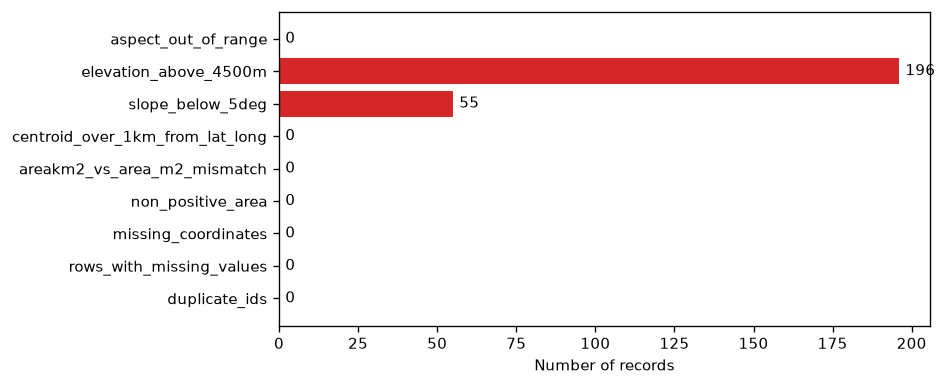

,count
duplicate_ids,0
rows_with_missing_values,0
missing_coordinates,0
non_positive_area,0
areakm2_vs_area_m2_mismatch,0
centroid_over_1km_from_lat_long,0
slope_below_5deg,55
elevation_above_4500m,196
aspect_out_of_range,0


In [4]:
from pyproj import Transformer

to_utm = Transformer.from_crs('EPSG:4326', CRS_UTM, always_xy=True)
lx, ly = to_utm.transform(ls['Long'].values, ls['Lat'].values)
centroid_offset_m = np.hypot(lx - ls['Centroid_X'], ly - ls['Centroid_Y'])

checks = {
    'records': len(ls),
    'duplicate_ids': int(ls['ID'].duplicated().sum()),
    'rows_with_missing_values': int(ls.isna().any(axis=1).sum()),
    'missing_coordinates': int(ls[['Centroid_X', 'Centroid_Y']].isna().any(axis=1).sum()),
    'non_positive_area': int((ls['Area_'] <= 0).sum()),
    'areakm2_vs_area_m2_mismatch': int((abs(ls['AreaKM2'] * 1e6 - ls['Area_']) > 10).sum()),
    'centroid_over_1km_from_lat_long': int((centroid_offset_m > 1000).sum()),
    'slope_below_5deg': int((ls['Slope'] < 5).sum()),
    'elevation_above_4500m': int((ls['Elevation'] > MAX_ELEV_M).sum()),
    'aspect_out_of_range': int(((ls['Aspect'] < 0) | (ls['Aspect'] > 360)).sum()),
}
RESULTS['data_checks'] = checks
chk = pd.Series(checks).drop('records')

# Visual: data-quality check results
plt.figure(figsize=(7, 3.4))
colors = ['#d62728' if v > 0 else '#2ca02c' for v in chk.values]
plt.barh(chk.index, chk.values, color=colors)
for i, v in enumerate(chk.values):
    plt.text(v + 2, i, str(v), va='center')
plt.xlabel('Number of records')
savefig('fig1a_data_checks')
chk.to_frame('count')

In [5]:
# Handle problems in memory only
ls = ls[~ls['ID'].duplicated()].dropna(subset=['Centroid_X', 'Centroid_Y']).copy()
ls['x'], ls['y'] = ls['Centroid_X'], ls['Centroid_Y']        # landslide location (UTM 45N, metres)
ls['radius_m'] = np.sqrt(ls['Area_'] / np.pi)                # radius of a circle with the landslide's area
ls['image_date'] = ls['Image_ID'].str.extract(r'_(\d{8})T')[0]
print(ls['image_date'].value_counts())

image_date
20241227    8794
20250101     284
20241220     132
Name: count, dtype: int64


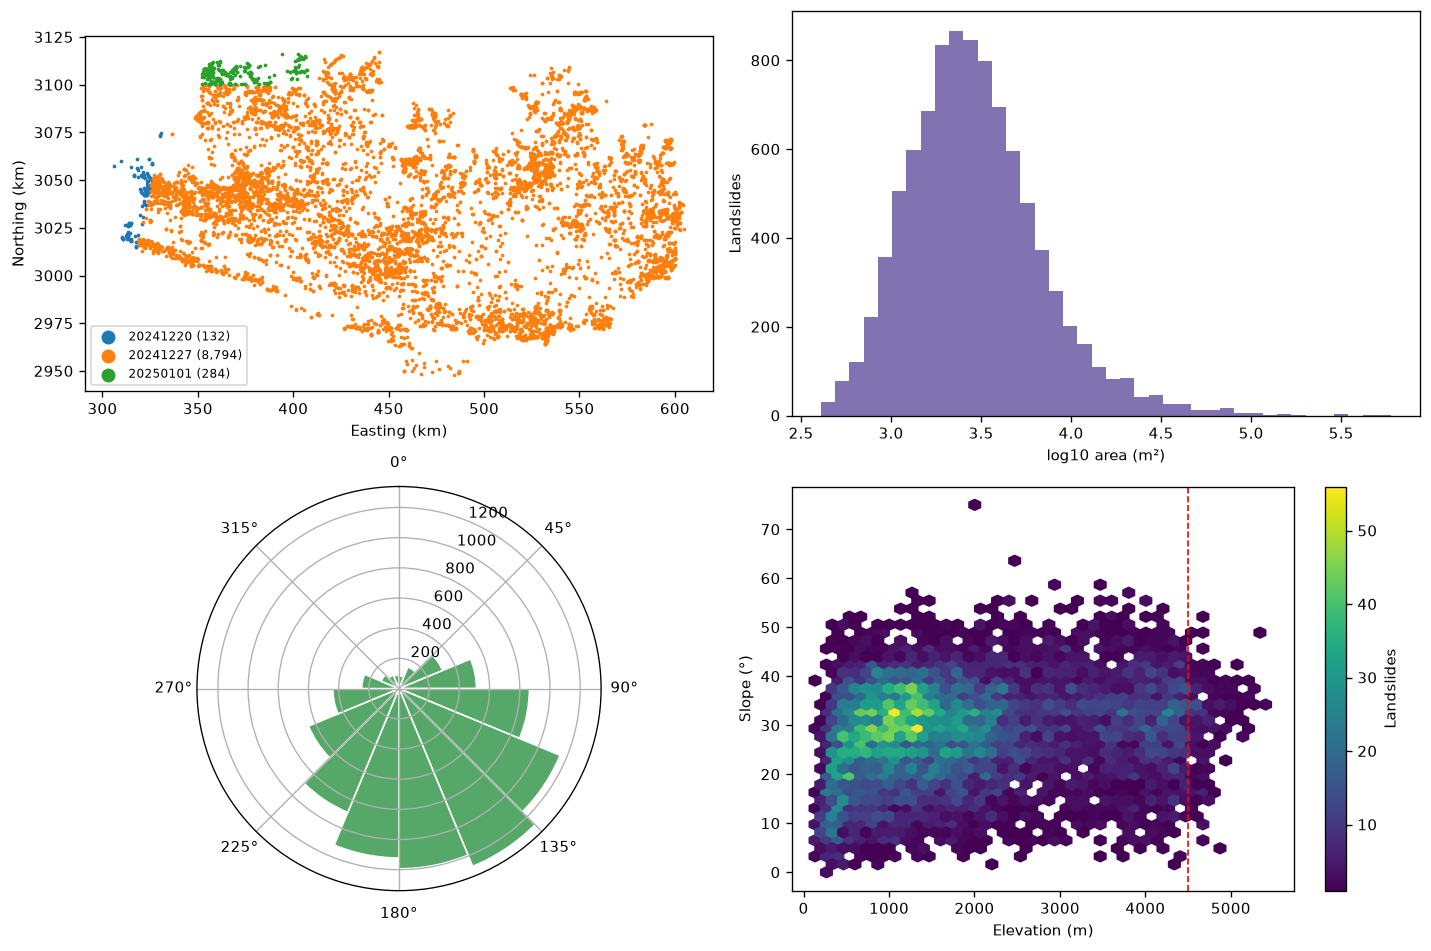

In [6]:
# Visual: inventory overview (map by image date, size, aspect rose, elevation vs slope)
fig = plt.figure(figsize=(12, 8))
ax1 = fig.add_subplot(2, 2, 1)
for d, c in zip(sorted(ls['image_date'].dropna().unique()), ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd']):
    s = ls[ls['image_date'] == d]
    ax1.scatter(s.x / 1000, s.y / 1000, s=1.5, c=c, label=f'{d} ({len(s):,})')
ax1.set_aspect('equal'); ax1.legend(markerscale=6, fontsize=7)
ax1.set_xlabel('Easting (km)'); ax1.set_ylabel('Northing (km)')

ax2 = fig.add_subplot(2, 2, 2)
ax2.hist(np.log10(ls['Area_']), bins=40, color='#8172b2')
ax2.set_xlabel('log10 area (m²)'); ax2.set_ylabel('Landslides')

ax3 = fig.add_subplot(2, 2, 3, projection='polar')
ax3.set_theta_zero_location('N'); ax3.set_theta_direction(-1)
h, e = np.histogram(ls['Aspect'], bins=np.arange(0, 361, 22.5))
ax3.bar(np.radians(e[:-1] + 11.25), h, width=np.radians(22.5), color='#55a868', edgecolor='w')


ax4 = fig.add_subplot(2, 2, 4)
hb = ax4.hexbin(ls['Elevation'], ls['Slope'], gridsize=40, cmap='viridis', mincnt=1)
fig.colorbar(hb, ax=ax4, label='Landslides'); ax4.axvline(MAX_ELEV_M, color='r', ls='--', lw=1)
ax4.set_xlabel('Elevation (m)'); ax4.set_ylabel('Slope (°)')
plt.tight_layout(); savefig('fig1b_inventory_overview')

## 2. DEM and terrain features
Both classes get their features from **the same SRTM DEM**, so the model cannot learn a difference between data
sources. Slope and aspect use Horn's 3x3 method; TRI follows Riley et al.; relief is max − min in an 11x11 window
(about 330 m).

In [7]:
import glob, math
import urllib.request, urllib.error
import rasterio
from rasterio.merge import merge
from pyproj import Transformer

to_ll = Transformer.from_crs(CRS_UTM, 'EPSG:4326', always_xy=True)
lon, lat = to_ll.transform(ls['x'].values, ls['y'].values)
W, E, S, N = lon.min() - 0.05, lon.max() + 0.05, lat.min() - 0.05, lat.max() + 0.05
print(f'DEM extent: {W:.2f}-{E:.2f} E, {S:.2f}-{N:.2f} N')

# 1. Use a DEM that is already on disk (this folder or ~/Desktop/Assign), if any
if not os.path.exists(DEM_PATH):
    found = [p for p in glob.glob('*.tif') + glob.glob(os.path.expanduser('~/Desktop/Assign/**/*.tif'), recursive=True)
             if os.path.getsize(p) > 1_000_000 and 'dem_tiles' not in p]
    if found:
        DEM_PATH = found[0]
print('DEM file:', DEM_PATH, '(found)' if os.path.exists(DEM_PATH) else '(will download)')

# 2. Otherwise download: SRTM from OpenTopography if a key is set, else Copernicus 30 m from AWS (no key)
if not os.path.exists(DEM_PATH) and OPENTOPO_KEY.strip():
    url = (f'https://portal.opentopography.org/API/globaldem?demtype={DEM_TYPE}&south={S:.4f}&north={N:.4f}'
           f'&west={W:.4f}&east={E:.4f}&outputFormat=GTiff&API_Key={OPENTOPO_KEY.strip()}')
    print('Downloading SRTM from OpenTopography (2-10 minutes)...')
    try:
        urllib.request.urlretrieve(url, DEM_PATH)
    except urllib.error.HTTPError as e:
        raise RuntimeError(f'OpenTopography error {e.code}: ' + e.read().decode(errors='ignore')[:300])
elif not os.path.exists(DEM_PATH):
    print('No API key: downloading Copernicus GLO-30 tiles from AWS (no key needed)...')
    os.makedirs('dem_tiles', exist_ok=True)
    paths = []
    for la in range(math.floor(S), math.floor(N) + 1):
        for lo in range(math.floor(W), math.floor(E) + 1):
            name = f'Copernicus_DSM_COG_10_N{la:02d}_00_E{lo:03d}_00_DEM'
            p = f'dem_tiles/{name}.tif'
            if not os.path.exists(p):
                try:
                    urllib.request.urlretrieve(f'https://copernicus-dem-30m.s3.amazonaws.com/{name}/{name}.tif', p)
                    print('  downloaded', name)
                except urllib.error.HTTPError:
                    print('  no tile', name); continue
            paths.append(p)
    srcs = [rasterio.open(p) for p in paths]
    mosaic, mosaic_T = merge(srcs, bounds=(W, S, E, N))
    meta = srcs[0].meta.copy()
    meta.update(height=mosaic.shape[1], width=mosaic.shape[2], transform=mosaic_T, compress='deflate')
    with rasterio.open(DEM_PATH, 'w', **meta) as dst:
        dst.write(mosaic)
    for s_ in srcs:
        s_.close()

# 3. Load the DEM
with rasterio.open(DEM_PATH) as src:
    dem = src.read(1).astype('float32'); T = src.transform; dem_crs = src.crs
    if src.nodata is not None:
        dem[dem == src.nodata] = np.nan
dem[dem < -500] = np.nan
assert dem_crs.to_epsg() == 4326, 'This notebook expects a DEM in geographic coordinates (EPSG:4326)'
print('DEM', dem.shape, '| resolution', round(T.a * 3600, 2), 'arc-seconds | rasterio', rasterio.__version__)

DEM extent: 84.98-88.11 E, 26.60-28.23 N
DEM file: dem_srtm.tif (will download)
No API key: downloading Copernicus GLO-30 tiles from AWS (no key needed)...
  downloaded Copernicus_DSM_COG_10_N26_00_E084_00_DEM
  downloaded Copernicus_DSM_COG_10_N26_00_E085_00_DEM
  downloaded Copernicus_DSM_COG_10_N26_00_E086_00_DEM
  downloaded Copernicus_DSM_COG_10_N26_00_E087_00_DEM
  downloaded Copernicus_DSM_COG_10_N26_00_E088_00_DEM
  downloaded Copernicus_DSM_COG_10_N27_00_E084_00_DEM
  downloaded Copernicus_DSM_COG_10_N27_00_E085_00_DEM
  downloaded Copernicus_DSM_COG_10_N27_00_E086_00_DEM
  downloaded Copernicus_DSM_COG_10_N27_00_E087_00_DEM
  downloaded Copernicus_DSM_COG_10_N27_00_E088_00_DEM
  downloaded Copernicus_DSM_COG_10_N28_00_E084_00_DEM
  downloaded Copernicus_DSM_COG_10_N28_00_E085_00_DEM
  downloaded Copernicus_DSM_COG_10_N28_00_E086_00_DEM
  downloaded Copernicus_DSM_COG_10_N28_00_E087_00_DEM
  downloaded Copernicus_DSM_COG_10_N28_00_E088_00_DEM
DEM (5856, 11256) | resolution 1.0

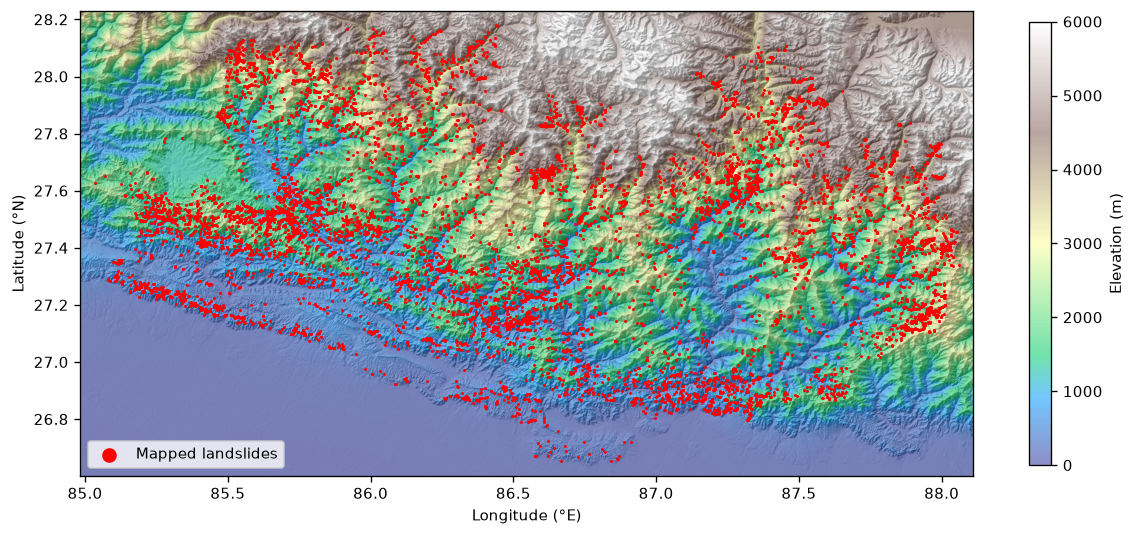

In [8]:
# Visual: hillshaded DEM with landslides overlaid
step = max(1, dem.shape[1] // 1500)                       # downsample for plotting speed
d = dem[::step, ::step]
gy, gx = np.gradient(np.nan_to_num(d, nan=np.nanmean(d)))
az, alt = np.radians(315), np.radians(45)                 # light from the north-west
slope_r = np.arctan(np.hypot(gx, gy) / 30)
aspect_r = np.arctan2(-gx, gy)
hill = np.sin(alt) * np.cos(slope_r) + np.cos(alt) * np.sin(slope_r) * np.cos(az - aspect_r)
extent = [T.c, T.c + T.a * dem.shape[1], T.f + T.e * dem.shape[0], T.f]
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(hill, cmap='gray', extent=extent, alpha=1)
im = ax.imshow(d, cmap='terrain', extent=extent, alpha=0.55, vmin=0, vmax=6000)
ax.scatter(lon, lat, s=0.6, c='red', label='Mapped landslides')
fig.colorbar(im, ax=ax, label='Elevation (m)', shrink=0.8)
ax.set_xlabel('Longitude (°E)'); ax.set_ylabel('Latitude (°N)'); ax.legend(markerscale=10, loc='lower left')

savefig('fig2a_dem_hillshade')

In [9]:
def terrain(lons, lats):
    """Elevation, slope, aspect, TRI and relief at many points, read straight from the DEM array."""
    lons, lats = np.asarray(lons), np.asarray(lats)
    cols = np.floor((lons - T.c) / T.a).astype(int)
    rows = np.floor((lats - T.f) / T.e).astype(int)
    H, Wd = dem.shape
    ok = (rows >= 5) & (rows < H - 5) & (cols >= 5) & (cols < Wd - 5)
    r, c = np.where(ok, rows, 5), np.where(ok, cols, 5)
    z = lambda dr, dc: dem[r + dr, c + dc]
    a, b, cc = z(-1, -1), z(-1, 0), z(-1, 1)
    d, e, f = z(0, -1), z(0, 0), z(0, 1)
    g, h, i = z(1, -1), z(1, 0), z(1, 1)
    dx = abs(T.a) * 111320 * np.cos(np.radians(lats))     # metres per pixel east
    dy = abs(T.e) * 110574                                 # metres per pixel north
    dzdx = ((cc + 2 * f + i) - (a + 2 * d + g)) / (8 * dx)  # rise towards east (Horn)
    dzdy = ((a + 2 * b + cc) - (g + 2 * h + i)) / (8 * dy)  # rise towards north
    slope = np.degrees(np.arctan(np.hypot(dzdx, dzdy)))
    aspect = (np.degrees(np.arctan2(-dzdx, -dzdy)) + 360) % 360  # direction the slope faces
    tri = np.sqrt(sum((n - e) ** 2 for n in (a, b, cc, d, f, g, h, i)))
    win = np.stack([z(dr, dc) for dr in range(-5, 6) for dc in range(-5, 6)])
    relief = np.nanmax(win, 0) - np.nanmin(win, 0)
    out = pd.DataFrame({'elevation': e, 'slope': slope, 'aspect': aspect, 'tri': tri, 'relief': relief})
    out.loc[~ok] = np.nan
    return out

# Sanity check on a synthetic plane rising to the east: aspect must be 270° (faces west)
_dem, _T = dem, T
dem = np.tile(np.arange(50, dtype='float32') * 10, (50, 1))
T = rasterio.Affine(1/3600, 0, 86, 0, -1/3600, 27)
_t = terrain([86 + 25/3600], [27 - 25/3600])
print('check: slope %.1f deg, aspect %.0f deg' % (_t.slope[0], _t.aspect[0]))
assert abs(_t.aspect[0] - 270) < 1
dem, T = _dem, _T

check: slope 19.9 deg, aspect 270 deg


Landslides kept: 9005 (dropped 0 DEM no-data, 205 above 4500 m)


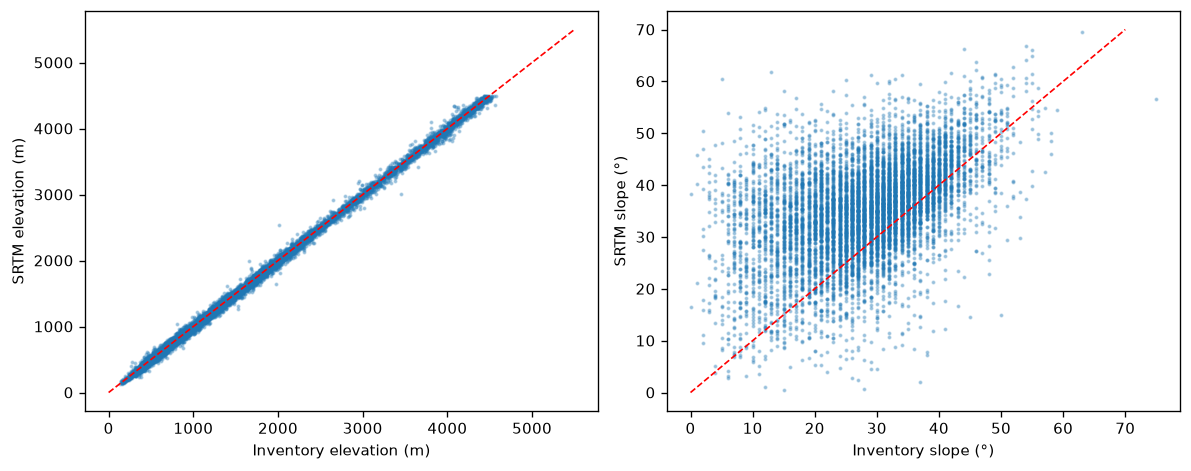

In [10]:
ls_t = terrain(lon, lat)
ls_feat = pd.concat([ls[['ID', 'x', 'y']].reset_index(drop=True), ls_t], axis=1)
n0 = len(ls_feat)
ls_feat = ls_feat.dropna()
dropped_nodata = n0 - len(ls_feat)
dropped_high = int((ls_feat['elevation'] > MAX_ELEV_M).sum())
ls_feat = ls_feat[ls_feat['elevation'] <= MAX_ELEV_M]
ls_feat['label'] = 1
print(f'Landslides kept: {len(ls_feat)} (dropped {dropped_nodata} DEM no-data, {dropped_high} above {MAX_ELEV_M} m)')
RESULTS['landslides_used'] = len(ls_feat); RESULTS['landslides_dropped_high'] = dropped_high

# Agreement between the inventory's own terrain values and SRTM
m = ls[['ID', 'Slope', 'Elevation']].merge(ls_feat[['ID', 'slope', 'elevation']], on='ID')
RESULTS['inventory_vs_srtm_corr'] = {'slope': round(float(m['Slope'].corr(m['slope'])), 3),
                                     'elevation': round(float(m['Elevation'].corr(m['elevation'])), 3)}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(m['Elevation'], m['elevation'], s=2, alpha=.3); ax[0].plot([0, 5500], [0, 5500], 'r--', lw=1)
ax[0].set_xlabel('Inventory elevation (m)'); ax[0].set_ylabel('SRTM elevation (m)')

ax[1].scatter(m['Slope'], m['slope'], s=2, alpha=.3); ax[1].plot([0, 70], [0, 70], 'r--', lw=1)
ax[1].set_xlabel('Inventory slope (°)'); ax[1].set_ylabel('SRTM slope (°)')

plt.tight_layout(); savefig('fig2b_inventory_vs_srtm')

## 3. Study area and background (class 0) samples
Background points are drawn at random inside the study area, below 4,500 m, on valid DEM cells, and at least 50 m
from every landslide. Each landslide is represented by a circle with its mapped area, so a candidate is rejected
if it is closer than (landslide radius + 50 m) to any landslide centroid. Sampling stops at a balanced 1:1 dataset.

In [11]:
import shapely
from shapely.geometry import Point
from scipy.spatial import cKDTree

if BOUNDARY_PATH:
    import geopandas as gpd
    area = gpd.read_file(BOUNDARY_PATH).to_crs(CRS_UTM).union_all()
else:
    area = shapely.concave_hull(shapely.MultiPoint(ls_feat[['x', 'y']].values), ratio=0.3).buffer(HULL_BUFFER_M)
print(f'Study area: {area.area / 1e6:,.0f} km2 | shapely', shapely.__version__)
RESULTS['study_area_km2'] = round(area.area / 1e6)

tree, rad = cKDTree(ls[['x', 'y']].values), ls['radius_m'].values
def too_close(xs, ys, k=20):
    """True where a point lies within (radius + 50 m) of any of its 20 nearest landslides."""
    d, j = tree.query(np.c_[xs, ys], k=k)
    return (d < rad[j] + EXCLUDE_BUFFER_M).any(axis=1)

rng = np.random.default_rng(SEED)
minx, miny, maxx, maxy = area.bounds
need, bg, tried = len(ls_feat), [], 0
while sum(len(b) for b in bg) < need:
    cand = pd.DataFrame({'x': rng.uniform(minx, maxx, 40000), 'y': rng.uniform(miny, maxy, 40000)})
    tried += len(cand)
    cand = cand[shapely.contains_xy(area, cand['x'].values, cand['y'].values)]
    cand = cand[~too_close(cand['x'].values, cand['y'].values)]
    blon, blat = to_ll.transform(cand['x'].values, cand['y'].values)
    t = terrain(blon, blat); t.index = cand.index
    g = pd.concat([cand, t], axis=1).dropna()
    bg.append(g[g['elevation'] <= MAX_ELEV_M])
bg = pd.concat(bg).iloc[:need].reset_index(drop=True)
bg['ID'] = -1; bg['label'] = 0

data = pd.concat([ls_feat, bg[ls_feat.columns]], ignore_index=True)
data['aspect_sin'] = np.sin(np.radians(data['aspect']))
data['aspect_cos'] = np.cos(np.radians(data['aspect']))
data['x_km'], data['y_km'] = data['x'] / 1000, data['y'] / 1000
data.to_csv(f'{OUT}/model_dataset.csv', index=False)
TERRAIN = ['elevation', 'slope', 'aspect_sin', 'aspect_cos', 'tri', 'relief']
FEATURES = TERRAIN + ['x_km', 'y_km']
RESULTS['n_samples'] = len(data)
print(f'Candidate points generated: {tried:,}; accepted: {len(bg):,}')
print(data['label'].value_counts().rename({1: 'landslide', 0: 'background'}))

Study area: 36,851 km2 | shapely 2.2.0
Candidate points generated: 40,000; accepted: 9,005
label
landslide     9005
background    9005
Name: count, dtype: int64


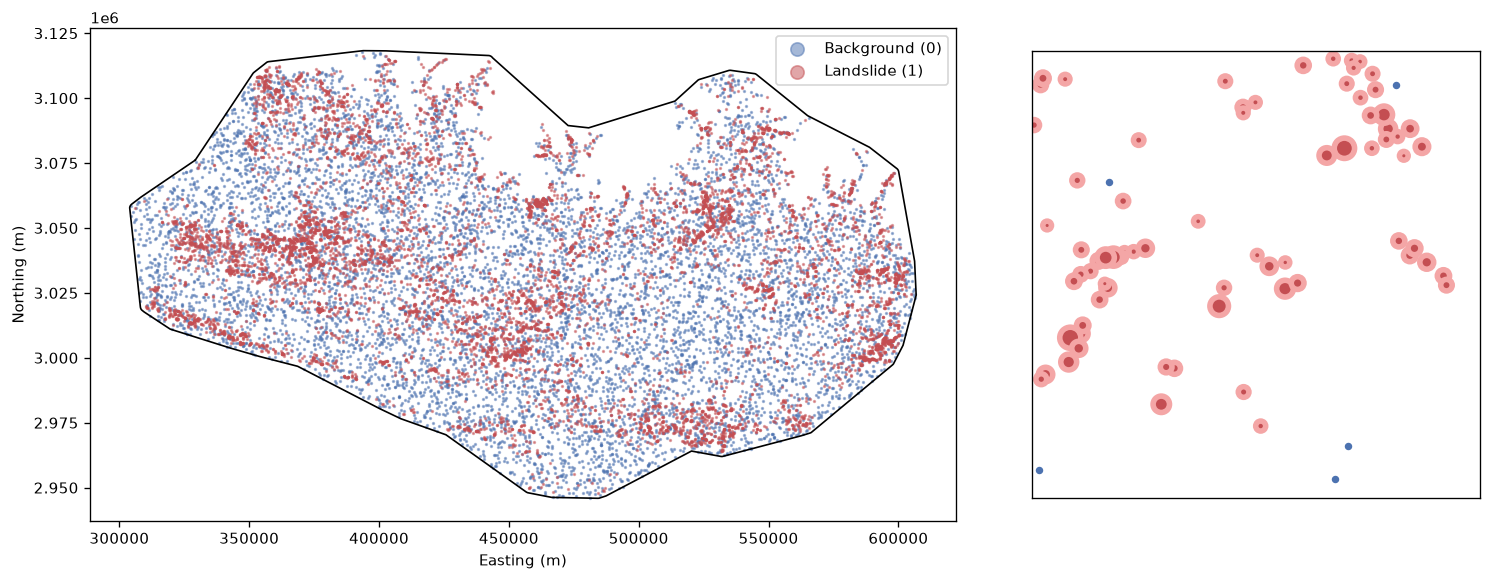

In [12]:
from matplotlib.patches import Circle

# Visual: study area, landslides and background samples
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [2.2, 1]})
for poly in shapely.get_parts(area):
    hx, hy = poly.exterior.xy; ax[0].plot(hx, hy, 'k-', lw=1)
ax[0].scatter(bg.x, bg.y, s=1, c='#4c72b0', alpha=.5, label='Background (0)')
ax[0].scatter(ls_feat.x, ls_feat.y, s=1, c='#c44e52', alpha=.5, label='Landslide (1)')
ax[0].set_aspect('equal'); ax[0].legend(markerscale=8)
ax[0].set_xlabel('Easting (m)'); ax[0].set_ylabel('Northing (m)')
# zoom on the densest landslide cluster to show the exclusion zones
Hd, xe, ye = np.histogram2d(ls.x, ls.y, bins=60)
i, j = np.unravel_index(Hd.argmax(), Hd.shape)
cx, cy, r = (xe[i] + xe[i + 1]) / 2, (ye[j] + ye[j + 1]) / 2, 2000
near = ls[ls.x.between(cx - r, cx + r) & ls.y.between(cy - r, cy + r)]
for _, s in near.iterrows():
    ax[1].add_patch(Circle((s.x, s.y), s.radius_m + EXCLUDE_BUFFER_M, fc='#f4a6a6', ec='none'))
    ax[1].add_patch(Circle((s.x, s.y), s.radius_m, fc='#c44e52', ec='none'))
z = bg[bg.x.between(cx - r, cx + r) & bg.y.between(cy - r, cy + r)]
ax[1].scatter(z.x, z.y, s=12, c='#4c72b0'); ax[1].set_xlim(cx - r, cx + r); ax[1].set_ylim(cy - r, cy + r)
ax[1].set_aspect('equal'); ax[1].set_xticks([]); ax[1].set_yticks([])

plt.tight_layout(); savefig('fig3a_study_area_samples')

## 4. Exploratory analysis, PCA and K-means

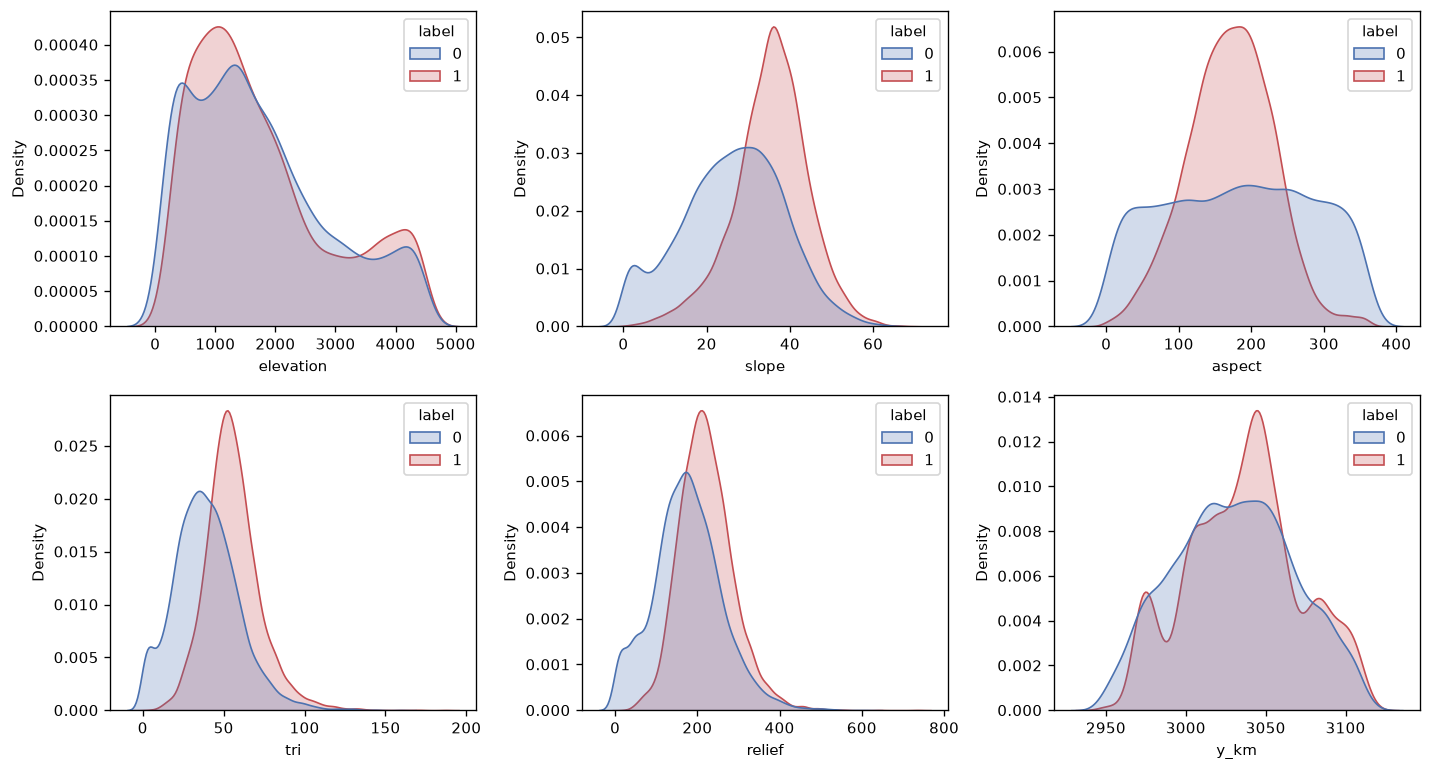

In [13]:
import seaborn as sns

# Visual: class distributions (density curves)
fig, axs = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, f in zip(axs.ravel(), ['elevation', 'slope', 'aspect', 'tri', 'relief', 'y_km']):
    sns.kdeplot(data=data, x=f, hue='label', common_norm=False, fill=True, ax=ax, palette=['#4c72b0', '#c44e52'])

plt.tight_layout(); savefig('fig3_class_distributions')

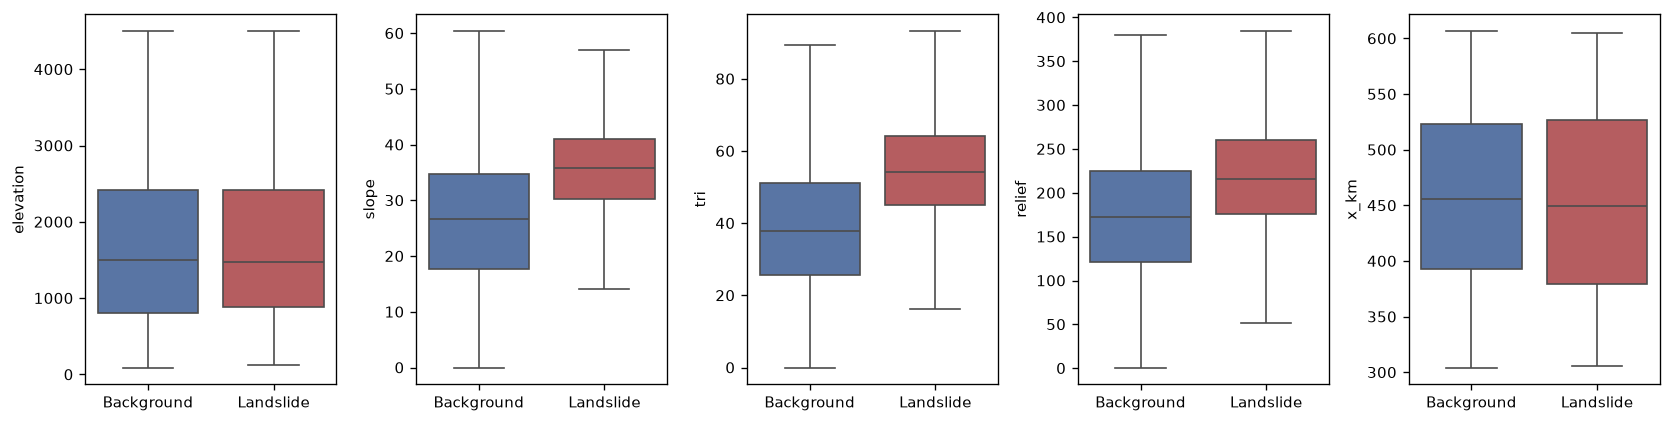

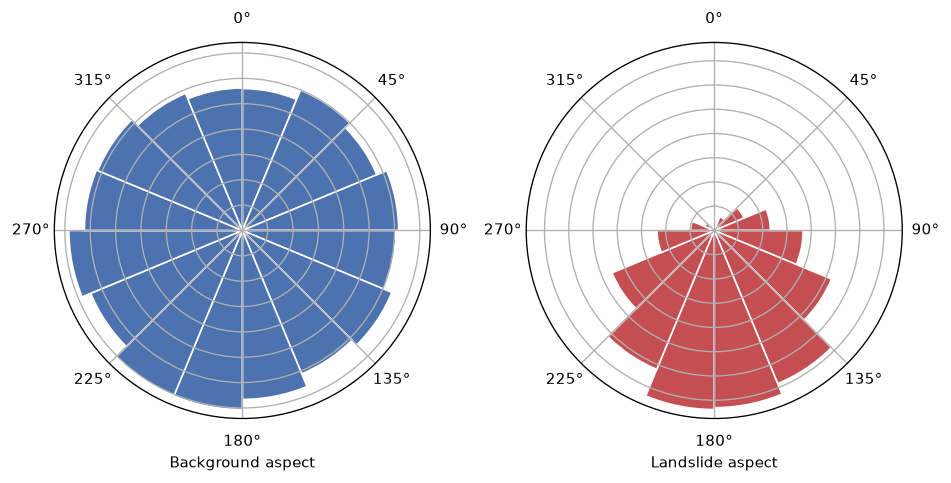

In [14]:
# Visual: box plots by class and aspect roses by class
fig, axs = plt.subplots(1, 5, figsize=(14, 3.6))
for ax, f in zip(axs, ['elevation', 'slope', 'tri', 'relief', 'x_km']):
    sns.boxplot(data=data, x='label', y=f, ax=ax, palette=['#4c72b0', '#c44e52'], showfliers=False)
    ax.set_xticklabels(['Background', 'Landslide']); ax.set_xlabel('')
plt.tight_layout(); savefig('fig3b_boxplots')

fig = plt.figure(figsize=(8, 4))
for k, (lab, col) in enumerate([(0, '#4c72b0'), (1, '#c44e52')]):
    ax = fig.add_subplot(1, 2, k + 1, projection='polar'); ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
    h, e = np.histogram(data.loc[data.label == lab, 'aspect'], bins=np.arange(0, 361, 22.5))
    ax.bar(np.radians(e[:-1] + 11.25), h / h.sum(), width=np.radians(22.5), color=col, edgecolor='w')
    ax.set_xlabel(['Background aspect', 'Landslide aspect'][lab]); ax.set_yticklabels([])
plt.tight_layout(); savefig('fig3c_aspect_roses')

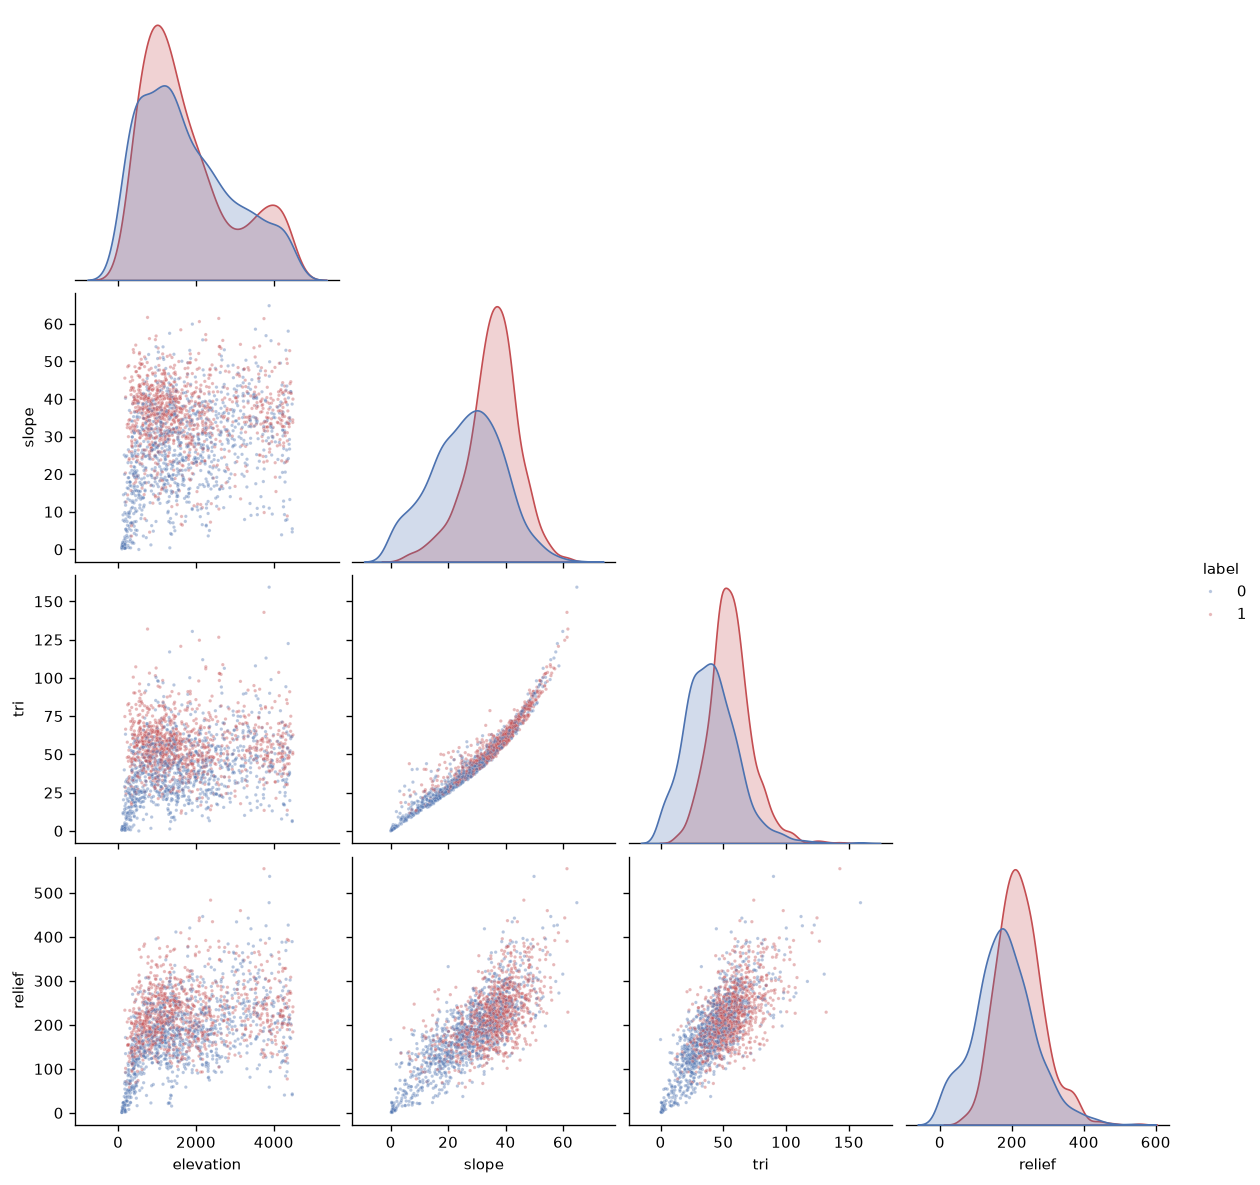

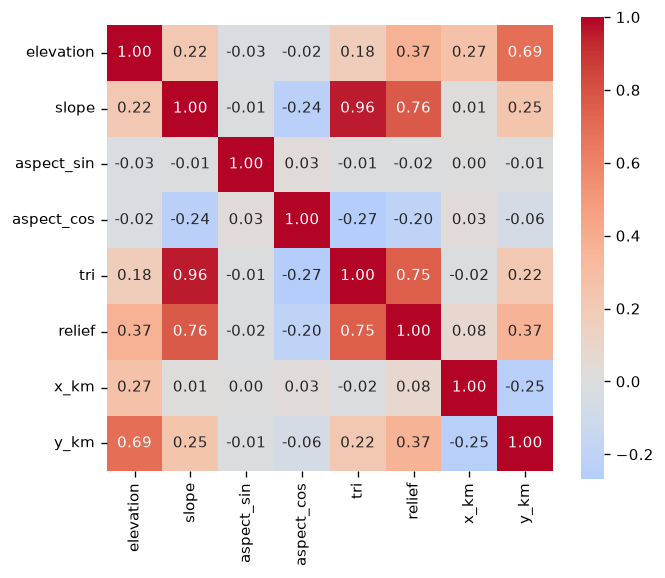

In [15]:
# Visual: pair plot on a sample and correlation heatmap
samp = data.sample(min(2000, len(data)), random_state=SEED)
g = sns.pairplot(samp[['elevation', 'slope', 'tri', 'relief', 'label']], hue='label',
                 palette=['#4c72b0', '#c44e52'], plot_kws={'s': 4, 'alpha': .4}, corner=True)

plt.savefig(f'{OUT}/fig3d_pairplot.png', dpi=150, bbox_inches='tight'); plt.show()

plt.figure(figsize=(6, 5))
sns.heatmap(data[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
savefig('fig4_correlation')

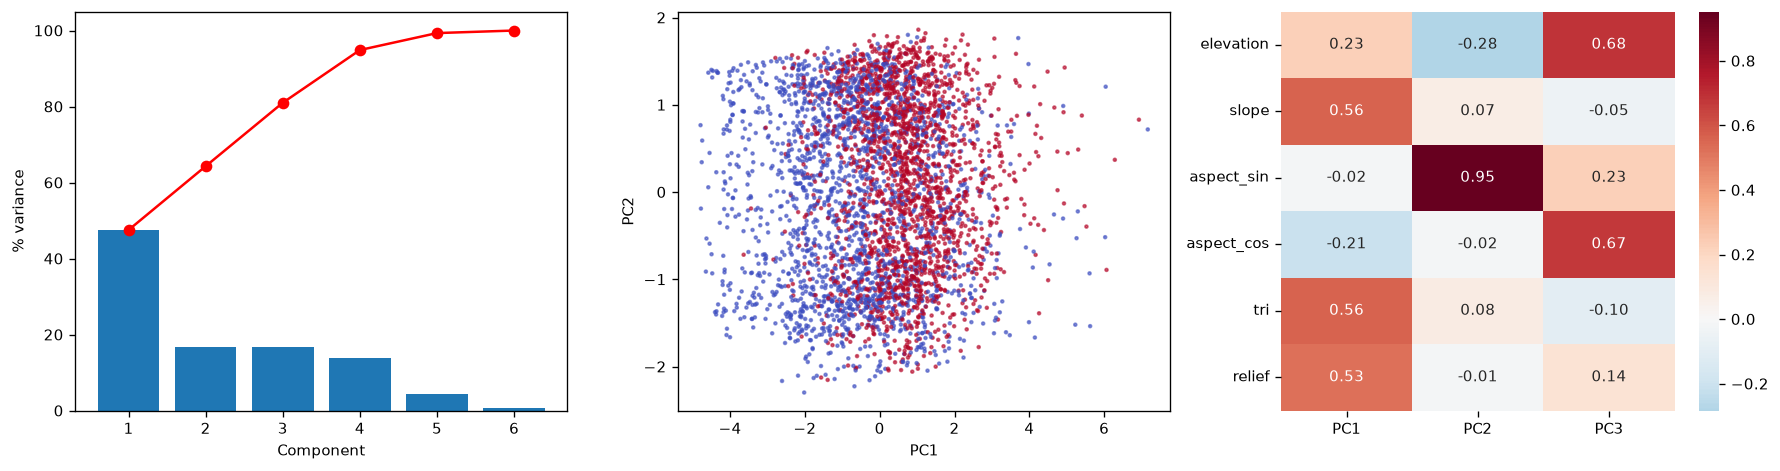

,PC1,PC2,PC3
elevation,0.23,-0.28,0.68
slope,0.56,0.07,-0.05
aspect_sin,-0.02,0.95,0.23
aspect_cos,-0.21,-0.02,0.67
tri,0.56,0.08,-0.10
relief,0.53,-0.01,0.14


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# PCA on standardised terrain features (feature extraction)
Z = StandardScaler().fit_transform(data[TERRAIN])
pca = PCA().fit(Z)
RESULTS['pca_explained_variance'] = [round(float(v), 3) for v in pca.explained_variance_ratio_]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
k = np.arange(1, len(TERRAIN) + 1)
ax[0].bar(k, pca.explained_variance_ratio_ * 100); ax[0].plot(k, np.cumsum(pca.explained_variance_ratio_) * 100, 'r-o')
ax[0].set_xlabel('Component'); ax[0].set_ylabel('% variance')
P = pca.transform(Z)[:, :2]; s = rng.choice(len(P), min(4000, len(P)), replace=False)
ax[1].scatter(P[s, 0], P[s, 1], c=data['label'].values[s], cmap='coolwarm', s=3, alpha=.6)
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2')
load = pd.DataFrame(pca.components_[:3].T, index=TERRAIN, columns=['PC1', 'PC2', 'PC3'])
sns.heatmap(load, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[2])
plt.tight_layout(); savefig('fig5_pca')
load.round(2)

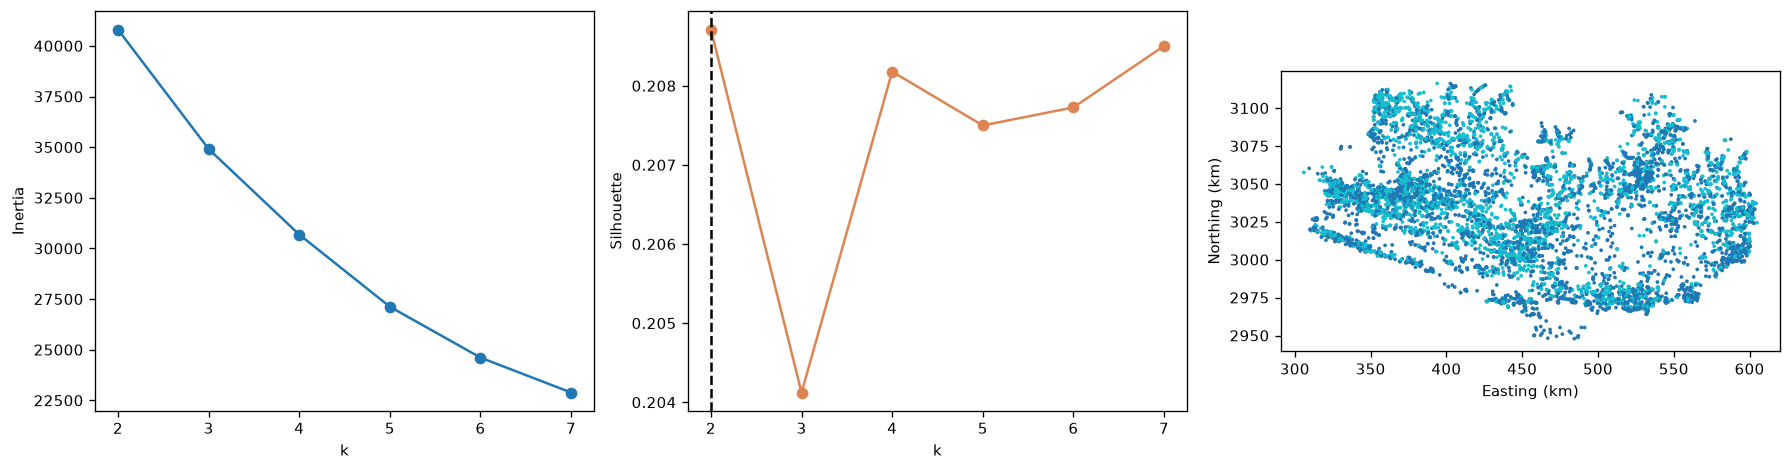

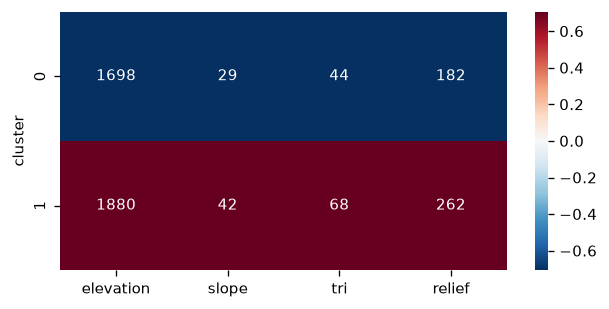

,elevation,slope,tri,relief,n
cluster,,,,,
0,1698.400024,29.1,44.099998,182.199997,4641
1,1880.300049,41.9,67.900002,262.399994,4364


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# K-means on landslide terrain only: are there distinct landslide terrain types?
ZL = StandardScaler().fit_transform(data.loc[data.label == 1, TERRAIN])
ks = range(2, 8); sil, inertia = {}, {}
for k in ks:
    km_k = KMeans(k, n_init=10, random_state=SEED).fit(ZL)
    sil[k] = silhouette_score(ZL, km_k.labels_, sample_size=4000, random_state=SEED); inertia[k] = km_k.inertia_
k_best = max(sil, key=sil.get)
km = KMeans(k_best, n_init=10, random_state=SEED).fit(ZL)
RESULTS['kmeans'] = {'silhouette': {k: round(float(v), 3) for k, v in sil.items()}, 'k_best': int(k_best)}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(list(inertia), list(inertia.values()), 'o-'); ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia')
ax[1].plot(list(sil), list(sil.values()), 'o-', c='#dd8452'); ax[1].axvline(k_best, ls='--', c='k')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette')
lsx = data.loc[data.label == 1]
ax[2].scatter(lsx.x_km, lsx.y_km, c=km.labels_, cmap='tab10', s=1.5); ax[2].set_aspect('equal')
ax[2].set_xlabel('Easting (km)'); ax[2].set_ylabel('Northing (km)')
plt.tight_layout(); savefig('fig5b_kmeans')

prof = lsx[['elevation', 'slope', 'tri', 'relief']].assign(cluster=km.labels_).groupby('cluster').mean()
plt.figure(figsize=(6, 2 + 0.4 * k_best))
sns.heatmap((prof - prof.mean()) / prof.std(), annot=prof.round(0), fmt='g', cmap='RdBu_r', center=0)
savefig('fig5c_cluster_profiles')
prof.assign(n=np.bincount(km.labels_)).round(1)

## 5. Spatial blocks and train/test split
Every point is assigned to a 10 km x 10 km block. 20% of blocks are held out as the final test set; tuning uses
5-fold GroupKFold on the remaining blocks, so no block is ever split between training and validation.

Blocks: 390 | train 14505 points, test 3505 points
Test class share: [0.5 0.5]


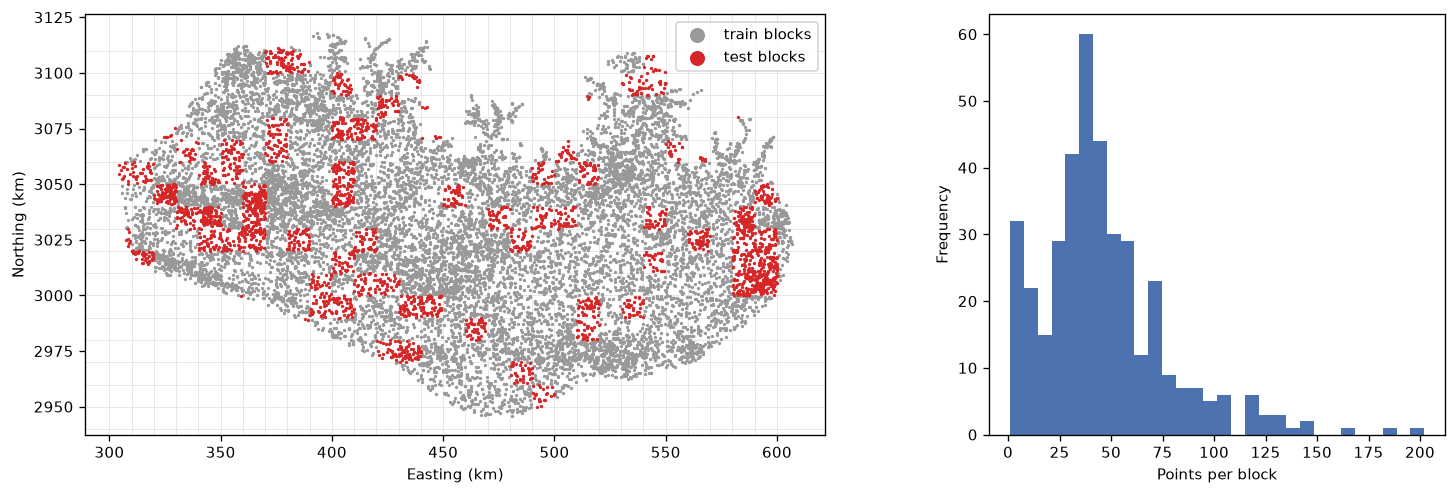

In [18]:
from sklearn.model_selection import GroupShuffleSplit

data['block'] = (np.floor(data['x'] / BLOCK_SIZE_M).astype(int).astype(str) + '_' +
                 np.floor(data['y'] / BLOCK_SIZE_M).astype(int).astype(str))
X, y, groups = data[FEATURES].astype('float64'), data['label'].values, data['block'].values
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=TEST_FRACTION, random_state=SEED).split(X, y, groups))
print(f'Blocks: {data.block.nunique()} | train {len(tr)} points, test {len(te)} points')
print('Test class share:', np.round(np.bincount(y[te]) / len(te), 3))
RESULTS['split'] = {'blocks': int(data.block.nunique()), 'train': int(len(tr)), 'test': int(len(te)),
                    'test_landslide_share': round(float(y[te].mean()), 3)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
ax[0].scatter(data.x_km.iloc[tr], data.y_km.iloc[tr], s=1, c='#999999', label='train blocks')
ax[0].scatter(data.x_km.iloc[te], data.y_km.iloc[te], s=1, c='#d62728', label='test blocks')
for xb in np.arange(np.floor(data.x.min() / BLOCK_SIZE_M), np.ceil(data.x.max() / BLOCK_SIZE_M)) * BLOCK_SIZE_M / 1000:
    ax[0].axvline(xb, c='#dddddd', lw=.4, zorder=0)
for yb in np.arange(np.floor(data.y.min() / BLOCK_SIZE_M), np.ceil(data.y.max() / BLOCK_SIZE_M)) * BLOCK_SIZE_M / 1000:
    ax[0].axhline(yb, c='#dddddd', lw=.4, zorder=0)
ax[0].set_aspect('equal'); ax[0].legend(markerscale=8)
ax[0].set_xlabel('Easting (km)'); ax[0].set_ylabel('Northing (km)')
data.groupby('block').size().plot.hist(bins=30, ax=ax[1], color='#4c72b0')
ax[1].set_xlabel('Points per block')
plt.tight_layout(); savefig('fig6_spatial_blocks')

## 6. Models, hyperparameter grids and spatial cross-validation

In [19]:
import time
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, GroupKFold

sc = lambda m: Pipeline([('scale', StandardScaler()), ('model', m)])   # scaler fitted inside each fold
q = QUICK
MODELS = {
  'Baseline (majority)': (DummyClassifier(strategy='prior'), {}),
  'Logistic Regression': (sc(LogisticRegression(max_iter=3000)), {'model__C': [0.1, 1] if q else [0.01, 0.1, 1, 10]}),
  'LDA':                 (sc(LinearDiscriminantAnalysis()), {}),
  'Gaussian Naive Bayes':(sc(GaussianNB()), {}),
  'KNN':                 (sc(KNeighborsClassifier()), {'model__n_neighbors': [15] if q else [5, 15, 31, 51],
                                                       'model__weights': ['distance'] if q else ['uniform', 'distance']}),
  'SVM (RBF)':           (sc(SVC(kernel='rbf', random_state=SEED)), {'model__C': [1] if q else [1, 10],
                                                                    'model__gamma': ['scale'] if q else ['scale', 0.1]}),
  'Decision Tree':       (DecisionTreeClassifier(random_state=SEED), {'max_depth': [5] if q else [3, 5, 8, 12, None],
                                                                    'min_samples_leaf': [10] if q else [1, 10, 50]}),
  'Random Forest':       (RandomForestClassifier(n_estimators=100 if q else 300, n_jobs=-1, random_state=SEED),
                          {'max_depth': [10] if q else [10, 20, None], 'min_samples_leaf': [5] if q else [1, 5]}),
  'Extra Trees':         (ExtraTreesClassifier(n_estimators=100 if q else 300, n_jobs=-1, random_state=SEED),
                          {'max_depth': [10] if q else [10, 20, None], 'min_samples_leaf': [5] if q else [1, 5]}),
  'Gradient Boosting':   (HistGradientBoostingClassifier(max_iter=100 if q else 300, random_state=SEED),
                          {'learning_rate': [0.1] if q else [0.05, 0.1], 'max_depth': [7] if q else [3, 7, None]}),
}

def score(m, Xs):
    """Probability of class 1 if available, otherwise the SVM decision function."""
    return m.predict_proba(Xs)[:, 1] if hasattr(m, 'predict_proba') else m.decision_function(Xs)

def fit_all(Xtr, ytr, gtr, cv):
    fitted = {}
    for name, (est, grid) in MODELS.items():
        t0 = time.time()
        if name.startswith('SVM') and len(Xtr) > SVM_TUNE_MAX:   # tune SVM on a subsample, refit on all
            idx = np.random.default_rng(SEED).choice(len(Xtr), SVM_TUNE_MAX, replace=False)
            gs = GridSearchCV(est, grid, cv=cv, scoring='roc_auc', n_jobs=-1)
            gs.fit(Xtr.iloc[idx], ytr[idx], groups=None if gtr is None else gtr[idx])
            best = gs.best_estimator_.fit(Xtr, ytr)
        else:
            gs = GridSearchCV(est, grid or {}, cv=cv, scoring='roc_auc', n_jobs=-1)
            gs.fit(Xtr, ytr, groups=gtr); best = gs.best_estimator_
        fitted[name] = dict(model=best, params=gs.best_params_, cv_auc=gs.best_score_,
                            cv_std=gs.cv_results_['std_test_score'][gs.best_index_], secs=time.time() - t0,
                            cv_table=pd.DataFrame(gs.cv_results_))
        print(f"{name:22s} CV AUC {gs.best_score_:.3f} ± {fitted[name]['cv_std']:.3f}  {gs.best_params_}  ({time.time()-t0:.0f}s)")
    return fitted

print('Spatial cross-validation (GroupKFold on blocks):')
spatial = fit_all(X.iloc[tr], y[tr], groups[tr], GroupKFold(n_splits=CV_FOLDS))

Spatial cross-validation (GroupKFold on blocks):
Baseline (majority)    CV AUC 0.500 ± 0.000  {}  (1s)
Logistic Regression    CV AUC 0.807 ± 0.014  {'model__C': 0.01}  (1s)
LDA                    CV AUC 0.806 ± 0.014  {}  (0s)
Gaussian Naive Bayes   CV AUC 0.800 ± 0.015  {}  (0s)
KNN                    CV AUC 0.838 ± 0.011  {'model__n_neighbors': 51, 'model__weights': 'distance'}  (1s)
SVM (RBF)              CV AUC 0.840 ± 0.008  {'model__C': 1, 'model__gamma': 0.1}  (4s)
Decision Tree          CV AUC 0.816 ± 0.012  {'max_depth': 8, 'min_samples_leaf': 50}  (0s)


/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop

Random Forest          CV AUC 0.847 ± 0.013  {'max_depth': 20, 'min_samples_leaf': 5}  (18s)


/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop

Extra Trees            CV AUC 0.844 ± 0.013  {'max_depth': 20, 'min_samples_leaf': 1}  (7s)
Gradient Boosting      CV AUC 0.850 ± 0.015  {'learning_rate': 0.05, 'max_depth': None}  (6s)


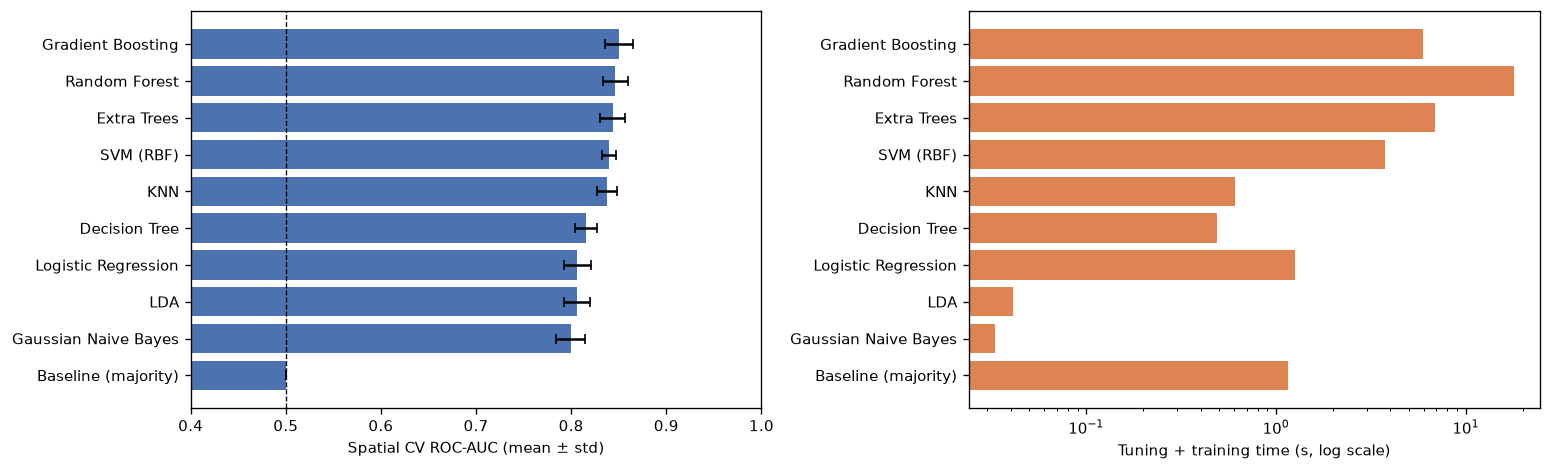

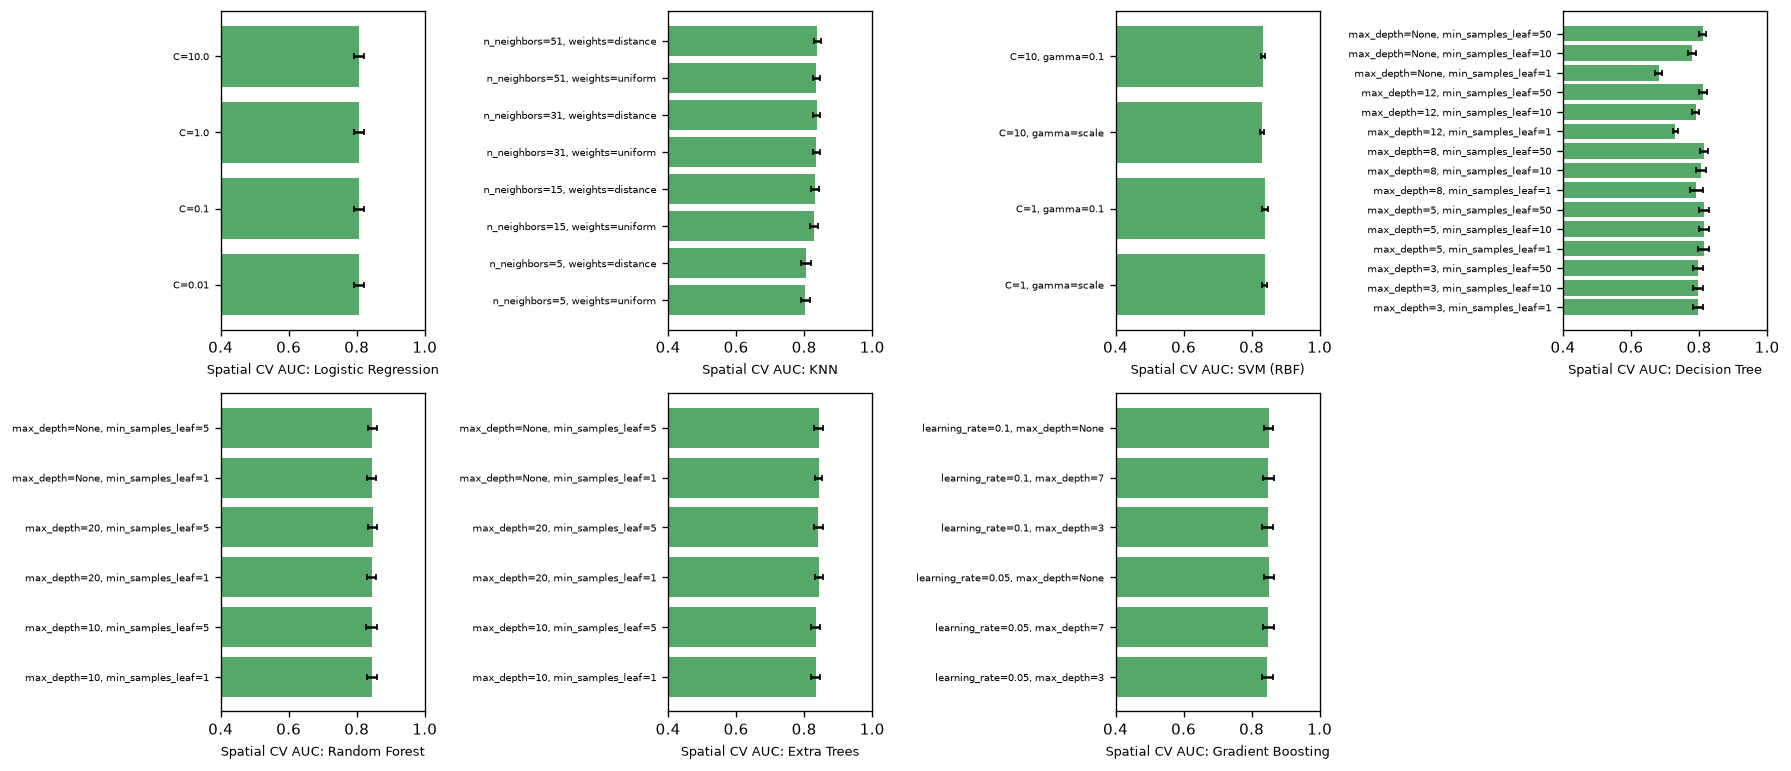

In [20]:
# Visual: cross-validated AUC with error bars, and training time
cvdf = pd.DataFrame({n: {'CV AUC': f['cv_auc'], 'std': f['cv_std'], 'secs': f['secs']} for n, f in spatial.items()}).T
cvdf = cvdf.sort_values('CV AUC')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(cvdf.index, cvdf['CV AUC'], xerr=cvdf['std'], color='#4c72b0', capsize=3)
ax[0].axvline(0.5, c='k', ls='--', lw=.8); ax[0].set_xlim(0.4, 1); ax[0].set_xlabel('Spatial CV ROC-AUC (mean ± std)')

ax[1].barh(cvdf.index, cvdf['secs'], color='#dd8452'); ax[1].set_xscale('log'); ax[1].set_xlabel('Tuning + training time (s, log scale)')

plt.tight_layout(); savefig('fig6b_cv_auc_and_time')

# Visual: hyperparameter effect for the tunable models
tunable = [n for n, (_, g) in MODELS.items() if g]
fig, axs = plt.subplots(2, (len(tunable) + 1) // 2, figsize=(15, 6.5))
for ax, n in zip(axs.ravel(), tunable):
    t = spatial[n]['cv_table']; pcols = [c for c in t.columns if c.startswith('param_')]
    lab = [', '.join(f"{c.replace('param_', '').replace('model__', '')}={v}" for c, v in row.items())
           for _, row in t[pcols].iterrows()]                # e.g. 'C=0.1' (works on all pandas versions)
    ax.barh(range(len(t)), t['mean_test_score'], xerr=t['std_test_score'], color='#55a868', capsize=2)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(lab, fontsize=6); ax.set_xlim(0.4, 1); ax.set_xlabel(f'Spatial CV AUC: {n}', fontsize=8)
for ax in axs.ravel()[len(tunable):]: ax.axis('off')
plt.tight_layout(); savefig('fig6c_hyperparameters')

## 7. Evaluation on spatially held-out test blocks (RQ1)

In [21]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef)

def evaluate(fitted, Xtr, ytr, Xte, yte):
    rows = []
    for name, f in fitted.items():
        m = f['model']; p = m.predict(Xte); s = score(m, Xte)
        rows.append({'Model': name, 'Accuracy': accuracy_score(yte, p), 'Balanced acc.': balanced_accuracy_score(yte, p),
                     'Precision': precision_score(yte, p, zero_division=0), 'Recall': recall_score(yte, p),
                     'F1': f1_score(yte, p, zero_division=0), 'ROC-AUC': roc_auc_score(yte, s),
                     'PR-AUC': average_precision_score(yte, s), 'MCC': matthews_corrcoef(yte, p),
                     'Train AUC': roc_auc_score(ytr, score(m, Xtr)), 'CV AUC': f['cv_auc'], 'CV std': f['cv_std'],
                     'Time (s)': f['secs'], 'Best params': str(f['params'])})
    return pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

res_sp = evaluate(spatial, X.iloc[tr], y[tr], X.iloc[te], y[te])
res_sp.to_csv(f'{OUT}/table_spatial_results.csv', index=False)
best_name = res_sp.loc[0, 'Model']; best = spatial[best_name]['model']
print('Best model under spatial validation:', best_name)
res_sp.drop(columns='Best params').round(3)

Best model under spatial validation: Gradient Boosting


,Model,Accuracy,Balanced acc.,Precision,Recall,F1,ROC-AUC,PR-AUC,MCC,Train AUC,CV AUC,CV std,Time (s)
0,Gradient Boosting,0.791,0.791,0.761,0.849,0.802,0.861,0.841,0.586,0.946,0.850,0.015,5.925
1,Random Forest,0.778,0.778,0.742,0.852,0.793,0.852,0.827,0.563,0.977,0.847,0.013,17.850
2,Extra Trees,0.771,0.772,0.739,0.839,0.786,0.845,0.818,0.548,1.000,0.844,0.013,6.864
3,SVM (RBF),0.777,0.778,0.734,0.870,0.796,0.844,0.809,0.565,0.852,0.840,0.008,3.769
4,KNN,0.770,0.770,0.736,0.842,0.786,0.839,0.815,0.546,1.000,0.838,0.011,0.606
5,Decision Tree,0.743,0.743,0.712,0.814,0.760,0.823,0.793,0.490,0.858,0.816,0.012,0.489
6,Logistic Regression,0.750,0.750,0.726,0.801,0.762,0.810,0.759,0.502,0.808,0.807,0.014,1.257
7,LDA,0.747,0.747,0.718,0.812,0.762,0.810,0.762,0.498,0.808,0.806,0.014,0.041
8,Gaussian Naive Bayes,0.752,0.752,0.721,0.821,0.768,0.804,0.746,0.509,0.801,0.800,0.015,0.033
9,Baseline (majority),0.500,0.500,0.500,1.000,0.666,0.500,0.500,0.000,0.500,0.500,0.000,1.161


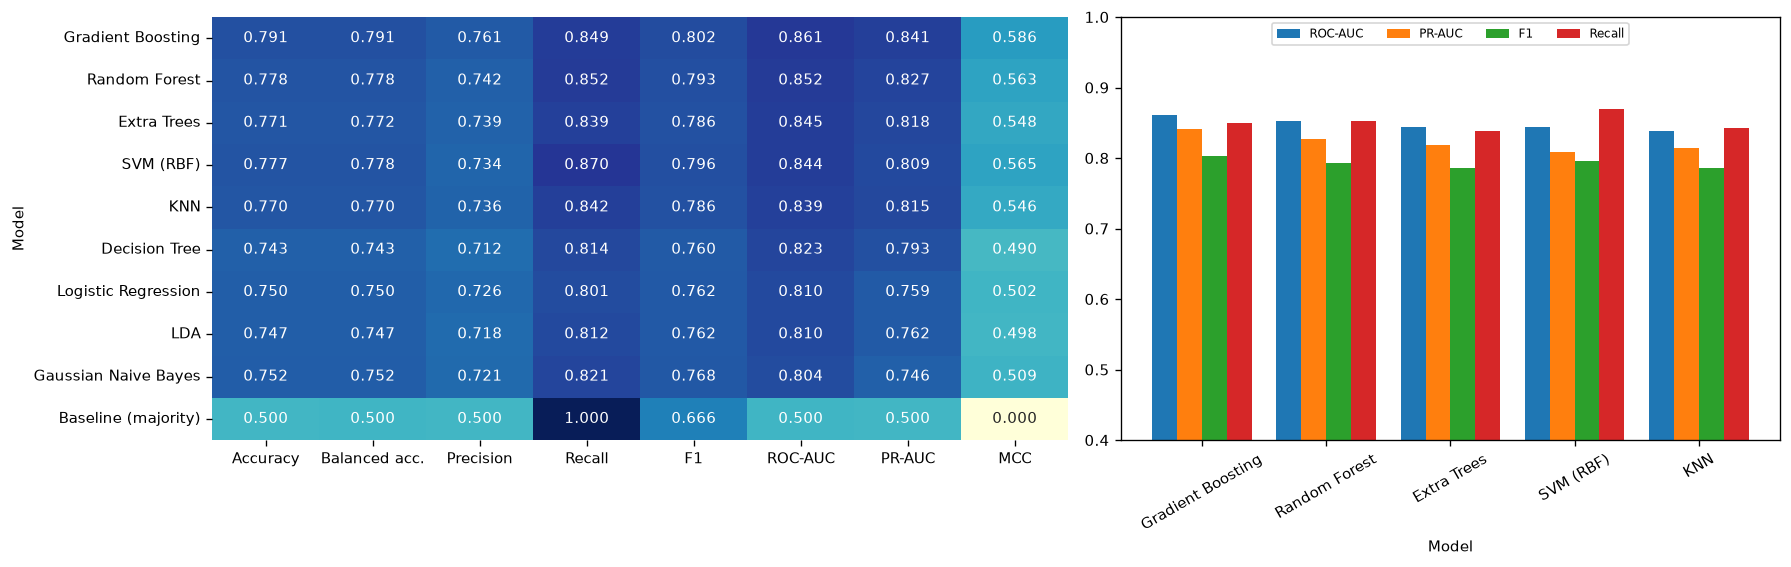

In [22]:
# Visual: metric heatmap (models x metrics) and grouped bar chart
mcols = ['Accuracy', 'Balanced acc.', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'MCC']
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
sns.heatmap(res_sp.set_index('Model')[mcols], annot=True, fmt='.3f', cmap='YlGnBu', ax=ax[0], cbar=False)

top5 = res_sp.head(5).set_index('Model')[['ROC-AUC', 'PR-AUC', 'F1', 'Recall']]
top5.plot.bar(ax=ax[1], rot=30, width=.8); ax[1].set_ylim(0.4, 1)
ax[1].legend(fontsize=7, ncol=4, loc='upper center')
plt.tight_layout(); savefig('fig7a_metrics_heatmap')

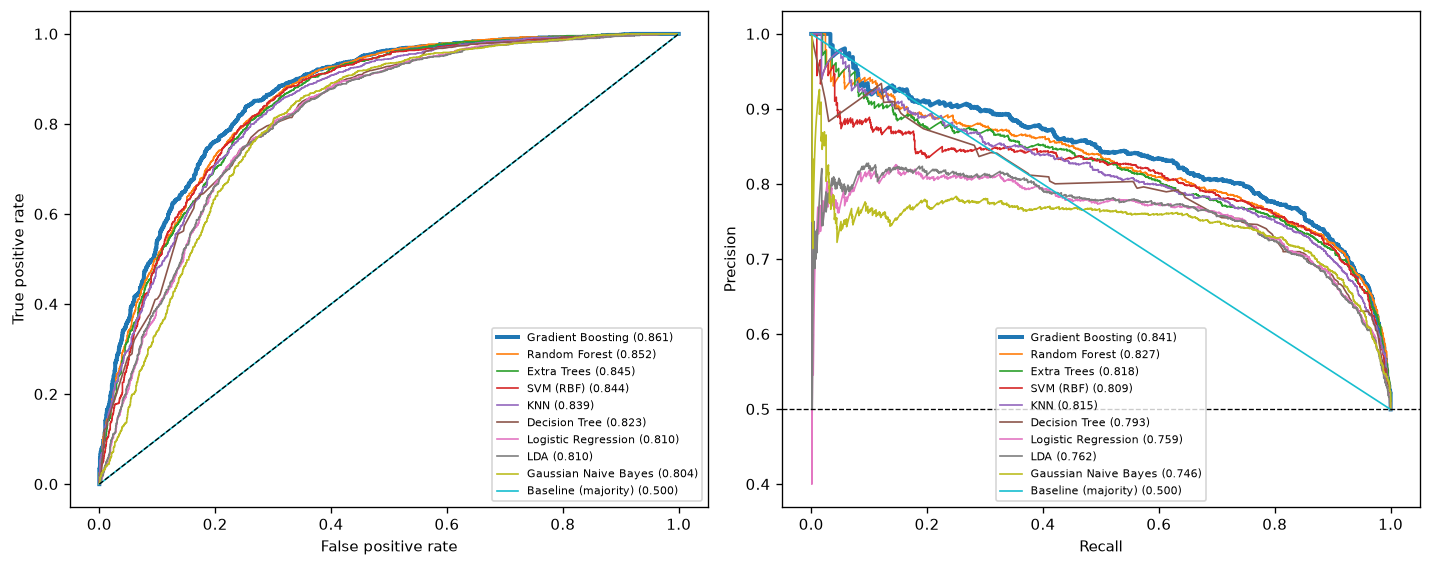

In [23]:
from sklearn.metrics import roc_curve, precision_recall_curve

# Visual: ROC and precision-recall curves for all models
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for name in res_sp['Model']:
    s = score(spatial[name]['model'], X.iloc[te])
    fpr, tpr, _ = roc_curve(y[te], s); pr, rc, _ = precision_recall_curve(y[te], s)
    lw = 2.4 if name == best_name else 1
    ax[0].plot(fpr, tpr, lw=lw, label=f'{name} ({roc_auc_score(y[te], s):.3f})')
    ax[1].plot(rc, pr, lw=lw, label=f'{name} ({average_precision_score(y[te], s):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')

ax[1].axhline(y[te].mean(), c='k', ls='--', lw=.8); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')

for a in ax: a.legend(fontsize=6.5)
plt.tight_layout(); savefig('fig7_roc_pr')

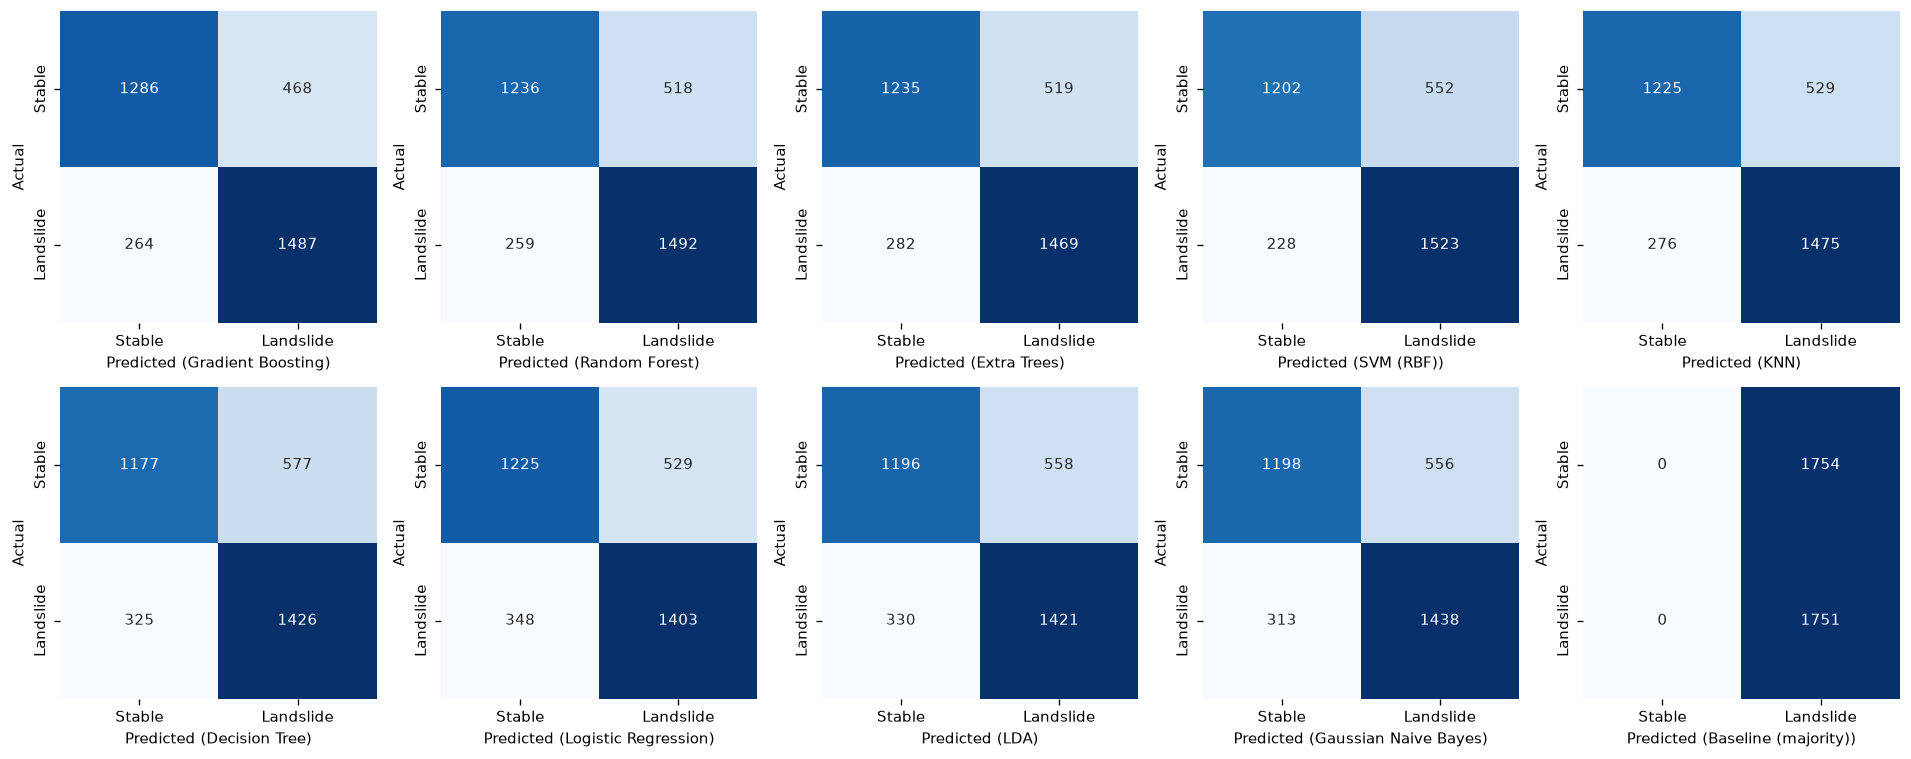

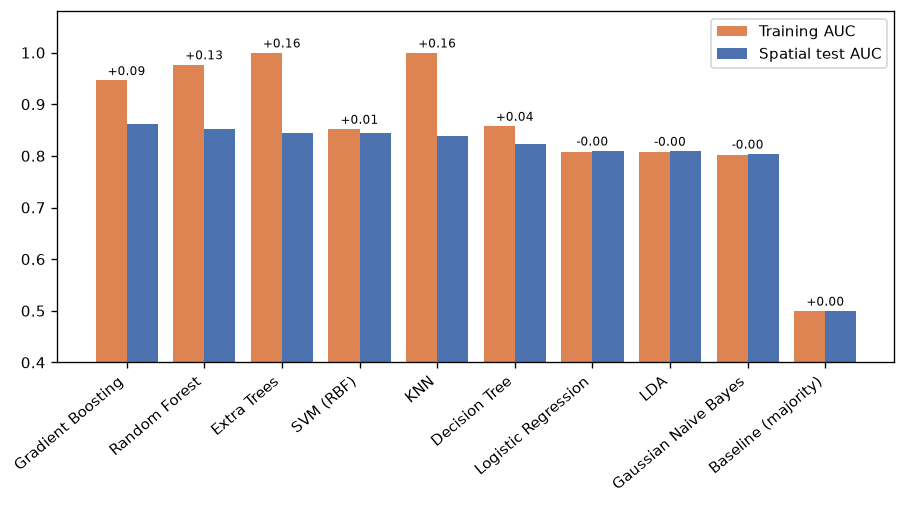

In [24]:
from sklearn.metrics import confusion_matrix

# Visual: confusion matrices for all ten models
fig, axs = plt.subplots(2, 5, figsize=(16, 6.4))
for a, name in zip(axs.ravel(), res_sp['Model']):
    cm = confusion_matrix(y[te], spatial[name]['model'].predict(X.iloc[te]))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['Stable', 'Landslide'], yticklabels=['Stable', 'Landslide'])
    a.set_xlabel(f'Predicted ({name})'); a.set_ylabel('Actual')
plt.tight_layout(); savefig('fig8_confusion_matrices')

# Visual: training vs test AUC (overfitting check)
plt.figure(figsize=(9, 3.8)); idx = np.arange(len(res_sp))
plt.bar(idx - .2, res_sp['Train AUC'], .4, label='Training AUC', color='#dd8452')
plt.bar(idx + .2, res_sp['ROC-AUC'], .4, label='Spatial test AUC', color='#4c72b0')
for i, (a, b) in enumerate(zip(res_sp['Train AUC'], res_sp['ROC-AUC'])):
    plt.text(i, max(a, b) + .01, f'{a - b:+.2f}', ha='center', fontsize=7)
plt.xticks(idx, res_sp['Model'], rotation=40, ha='right'); plt.ylim(.4, 1.08); plt.legend()
savefig('fig9_train_vs_test')

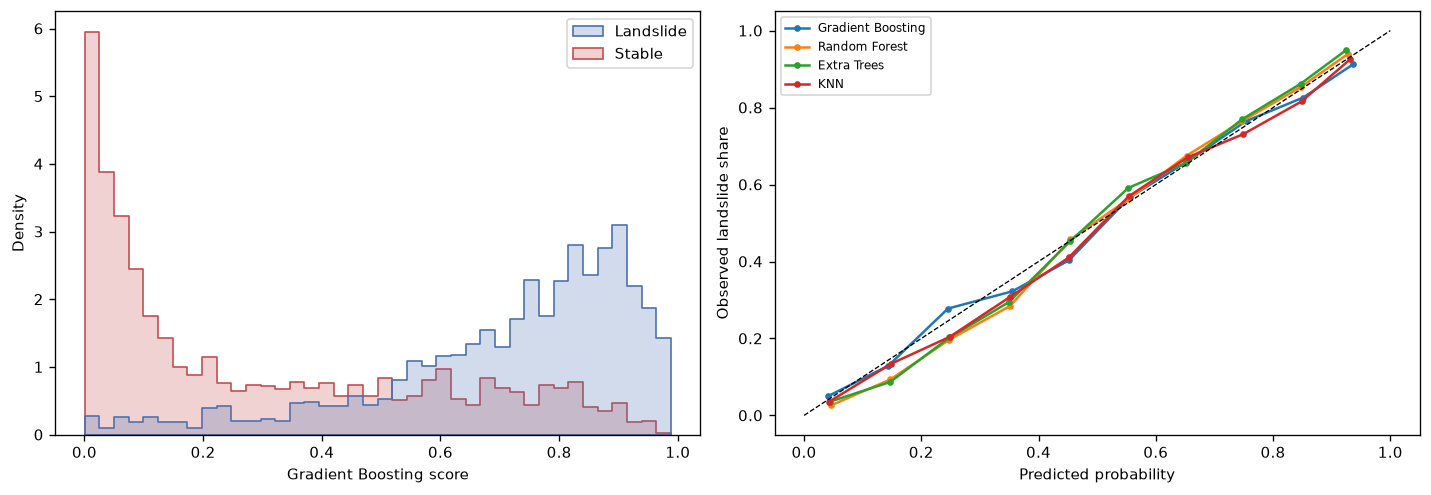

In [25]:
from sklearn.calibration import calibration_curve

# Visual: predicted probability by class, and calibration of the top probabilistic models
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sb = score(best, X.iloc[te])
sns.histplot(x=sb, hue=np.where(y[te] == 1, 'Landslide', 'Stable'), bins=40, stat='density',
             common_norm=False, element='step', ax=ax[0], palette=['#4c72b0', '#c44e52'])
ax[0].set_xlabel(f'{best_name} score')
for name in [n for n in res_sp['Model'] if hasattr(spatial[n]['model'], 'predict_proba') and 'Baseline' not in n][:4]:
    pt, pp = calibration_curve(y[te], spatial[name]['model'].predict_proba(X.iloc[te])[:, 1], n_bins=10)
    ax[1].plot(pp, pt, 'o-', ms=3, label=name)
ax[1].plot([0, 1], [0, 1], 'k--', lw=.8); ax[1].set_xlabel('Predicted probability'); ax[1].set_ylabel('Observed landslide share')
ax[1].legend(fontsize=7)
plt.tight_layout(); savefig('fig9b_scores_calibration')

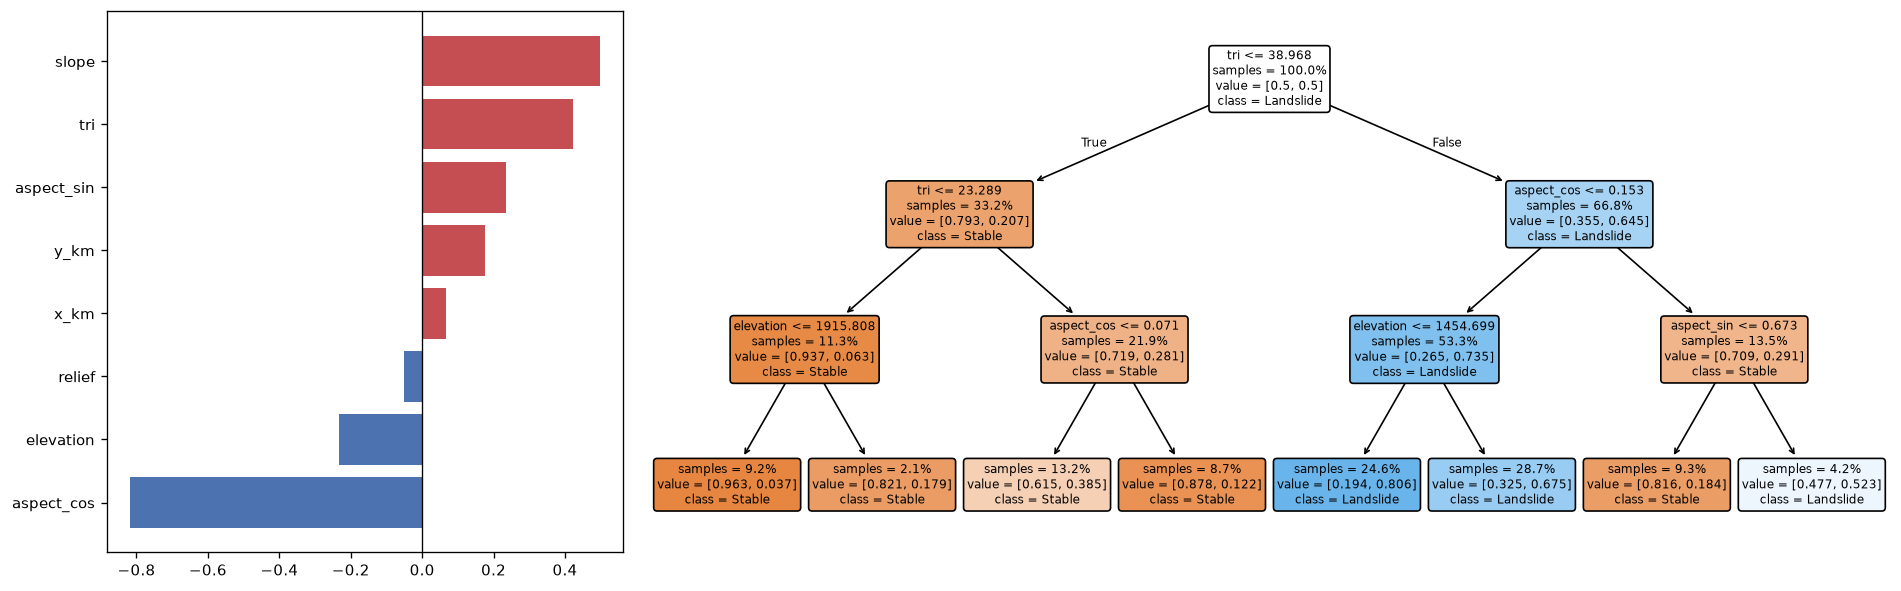

In [26]:
from sklearn.tree import plot_tree

# Visual: interpretable models — logistic regression coefficients and a shallow decision tree
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1, 2.4]})
lr = spatial['Logistic Regression']['model'].named_steps['model']
coef = pd.Series(lr.coef_[0], index=FEATURES).sort_values()
ax[0].barh(coef.index, coef.values, color=['#4c72b0' if v < 0 else '#c44e52' for v in coef.values])
ax[0].axvline(0, c='k', lw=.8)
small = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED).fit(X.iloc[tr], y[tr])
plot_tree(small, feature_names=FEATURES, class_names=['Stable', 'Landslide'], filled=True, rounded=True,
          fontsize=7, ax=ax[1], impurity=False, proportion=True)

plt.tight_layout(); savefig('fig9c_interpretable_models')

## 8. Random split vs spatial split (RQ3)

In [27]:
from sklearn.model_selection import train_test_split, StratifiedKFold

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, y, test_size=TEST_FRACTION, stratify=y, random_state=SEED)
print('Random cross-validation (StratifiedKFold):')
rand = fit_all(Xr_tr, yr_tr, None, StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED))
res_rd = evaluate(rand, Xr_tr, yr_tr, Xr_te, yr_te)
res_rd.to_csv(f'{OUT}/table_random_results.csv', index=False)
cmp = res_sp[['Model', 'ROC-AUC', 'F1']].merge(res_rd[['Model', 'ROC-AUC', 'F1']], on='Model', suffixes=(' spatial', ' random'))
cmp['AUC inflation'] = cmp['ROC-AUC random'] - cmp['ROC-AUC spatial']
cmp.to_csv(f'{OUT}/table_random_vs_spatial.csv', index=False)
cmp.round(3)

Random cross-validation (StratifiedKFold):
Baseline (majority)    CV AUC 0.500 ± 0.000  {}  (0s)
Logistic Regression    CV AUC 0.809 ± 0.004  {'model__C': 0.1}  (0s)
LDA                    CV AUC 0.808 ± 0.005  {}  (0s)
Gaussian Naive Bayes   CV AUC 0.803 ± 0.003  {}  (0s)
KNN                    CV AUC 0.848 ± 0.005  {'model__n_neighbors': 31, 'model__weights': 'distance'}  (0s)
SVM (RBF)              CV AUC 0.843 ± 0.015  {'model__C': 1, 'model__gamma': 0.1}  (4s)
Decision Tree          CV AUC 0.833 ± 0.003  {'max_depth': 12, 'min_samples_leaf': 50}  (0s)


/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop

Random Forest          CV AUC 0.862 ± 0.005  {'max_depth': None, 'min_samples_leaf': 1}  (17s)


/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop/Assign/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/kaushaldon/Desktop

Extra Trees            CV AUC 0.858 ± 0.004  {'max_depth': 20, 'min_samples_leaf': 1}  (7s)
Gradient Boosting      CV AUC 0.874 ± 0.005  {'learning_rate': 0.05, 'max_depth': 7}  (6s)


,Model,ROC-AUC spatial,F1 spatial,ROC-AUC random,F1 random,AUC inflation
0,Gradient Boosting,0.861,0.802,0.866,0.797,0.005
1,Random Forest,0.852,0.793,0.853,0.785,0.001
2,Extra Trees,0.845,0.786,0.852,0.786,0.008
3,SVM (RBF),0.844,0.796,0.841,0.787,-0.003
4,KNN,0.839,0.786,0.845,0.785,0.006
5,Decision Tree,0.823,0.760,0.826,0.748,0.003
6,Logistic Regression,0.810,0.762,0.808,0.750,-0.002
7,LDA,0.810,0.762,0.808,0.751,-0.002
8,Gaussian Naive Bayes,0.804,0.768,0.803,0.754,-0.002
9,Baseline (majority),0.500,0.666,0.500,0.000,0.000


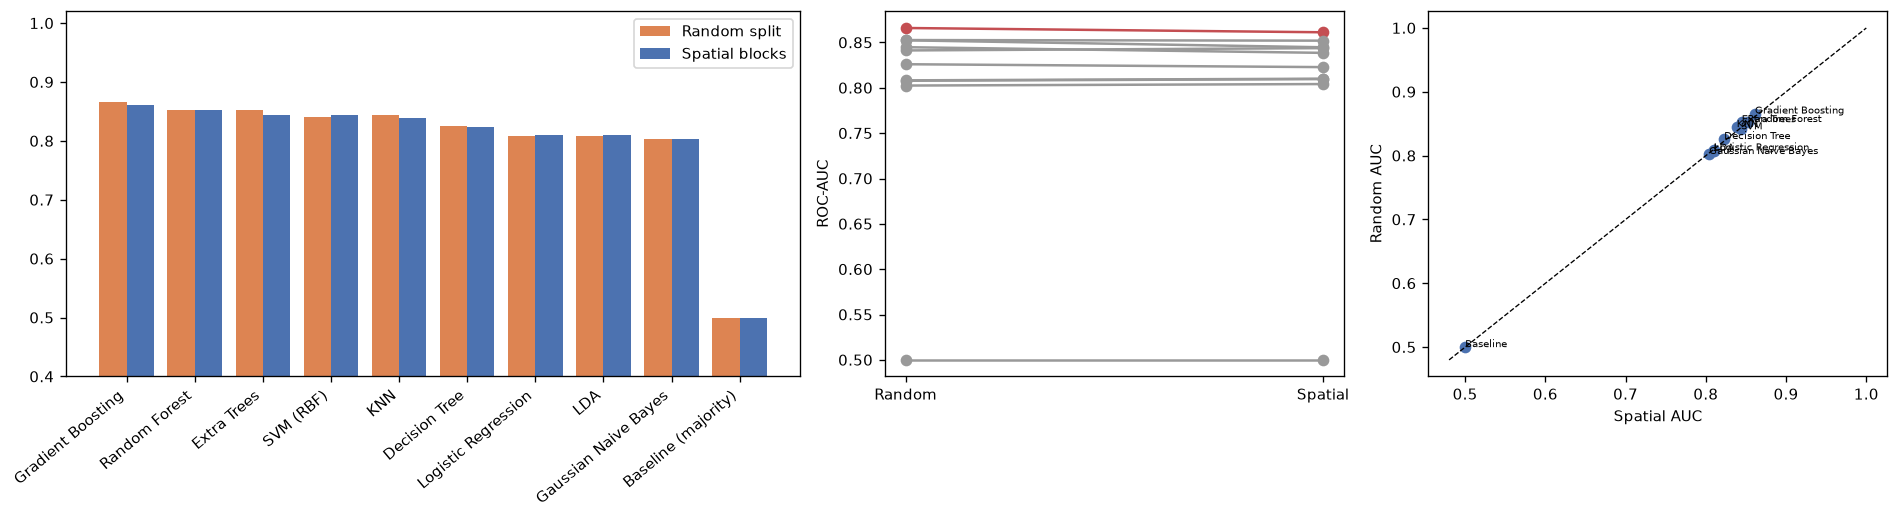

In [28]:
# Visual: paired bars, slope chart and scatter against the 1:1 line
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={'width_ratios': [1.6, 1, 1]})
idx = np.arange(len(cmp))
ax[0].bar(idx - .2, cmp['ROC-AUC random'], .4, label='Random split', color='#dd8452')
ax[0].bar(idx + .2, cmp['ROC-AUC spatial'], .4, label='Spatial blocks', color='#4c72b0')
ax[0].set_xticks(idx); ax[0].set_xticklabels(cmp['Model'], rotation=40, ha='right'); ax[0].set_ylim(.4, 1.02)
ax[0].legend()
for _, r in cmp.iterrows():
    ax[1].plot([0, 1], [r['ROC-AUC random'], r['ROC-AUC spatial']], 'o-', c='#c44e52' if r['Model'] == best_name else '#999999')
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(['Random', 'Spatial']); ax[1].set_ylabel('ROC-AUC')
ax[2].scatter(cmp['ROC-AUC spatial'], cmp['ROC-AUC random'], c='#4c72b0')
for _, r in cmp.iterrows():
    ax[2].annotate(r['Model'].split(' (')[0], (r['ROC-AUC spatial'], r['ROC-AUC random']), fontsize=6)
lo = min(cmp[['ROC-AUC spatial', 'ROC-AUC random']].min()) - .02
ax[2].plot([lo, 1], [lo, 1], 'k--', lw=.8); ax[2].set_xlabel('Spatial AUC'); ax[2].set_ylabel('Random AUC')

plt.tight_layout(); savefig('fig10_random_vs_spatial')

## 9. Feature importance and partial dependence (RQ2)

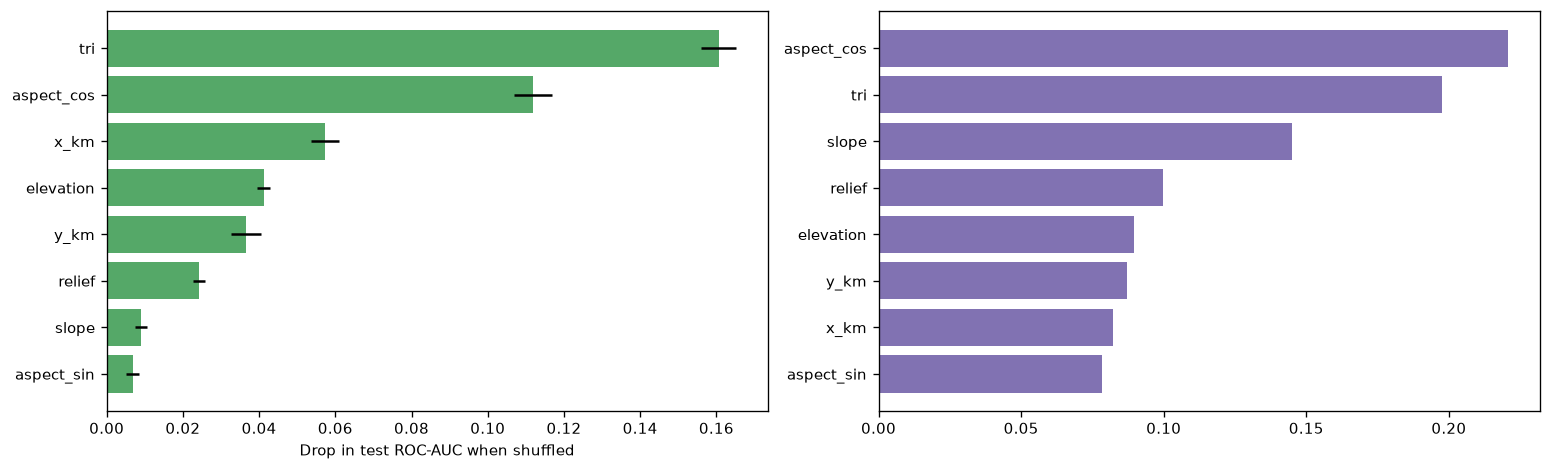

In [29]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(best, X.iloc[te], y[te], scoring='roc_auc', n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({'feature': FEATURES, 'importance': pi.importances_mean, 'std': pi.importances_std}).sort_values('importance')
imp.to_csv(f'{OUT}/table_feature_importance.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(imp['feature'], imp['importance'], xerr=imp['std'], color='#55a868')
ax[0].set_xlabel('Drop in test ROC-AUC when shuffled')
rf = spatial['Random Forest']['model']
gini = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
ax[1].barh(gini.index, gini.values, color='#8172b2')
plt.tight_layout(); savefig('fig11_feature_importance')

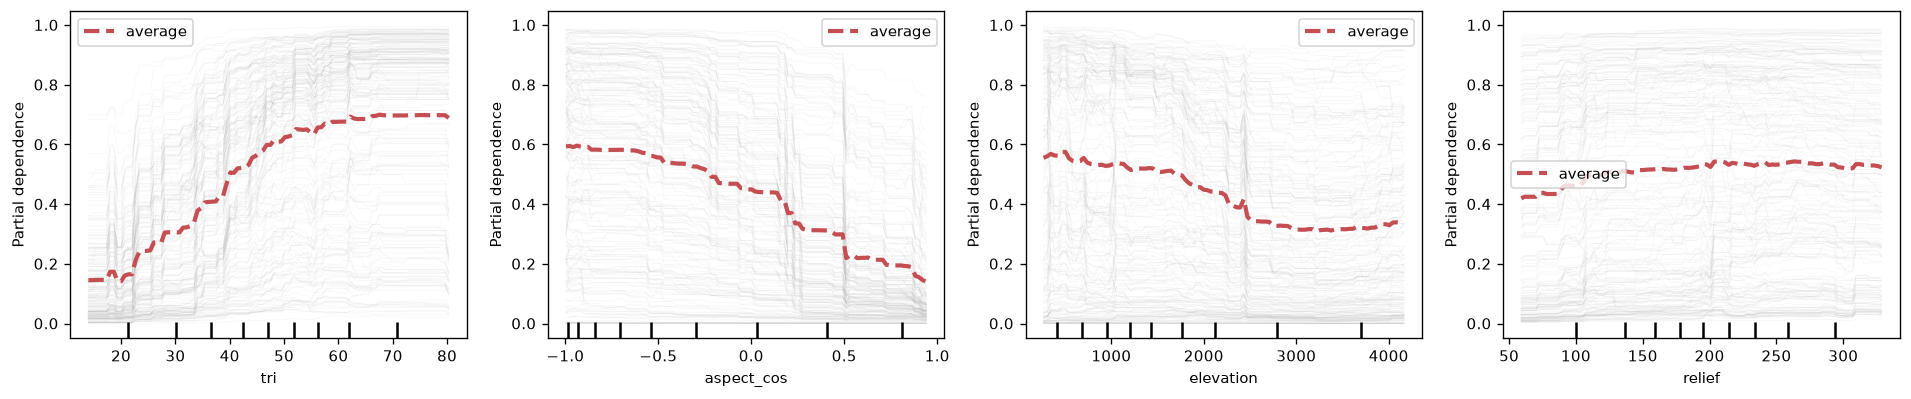

In [30]:
from sklearn.inspection import PartialDependenceDisplay

# Visual: how predicted susceptibility changes with each top terrain feature
top_feats = [f for f in imp.sort_values('importance', ascending=False)['feature'] if f in TERRAIN][:4]
fig, ax = plt.subplots(1, len(top_feats), figsize=(4 * len(top_feats), 3.4))
PartialDependenceDisplay.from_estimator(best, X.iloc[tr].sample(min(3000, len(tr)), random_state=SEED), top_feats,
                                        kind='both', subsample=200, ax=ax, random_state=SEED,
                                        ice_lines_kw={'alpha': .08, 'color': '#999999'}, pd_line_kw={'color': '#c44e52', 'lw': 2.5})
plt.tight_layout()
savefig('fig11b_partial_dependence')

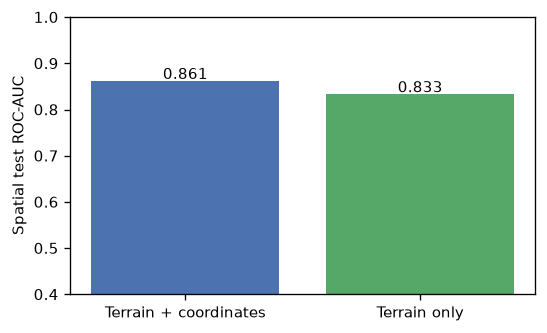

In [31]:
# Ablation: terrain only (no coordinates), best model type, same spatial split
abl_est, abl_grid = MODELS[best_name]
gs = GridSearchCV(abl_est, abl_grid or {}, cv=GroupKFold(CV_FOLDS), scoring='roc_auc', n_jobs=-1)
gs.fit(X.iloc[tr][TERRAIN], y[tr], groups=groups[tr])
auc_terrain = roc_auc_score(y[te], score(gs.best_estimator_, X.iloc[te][TERRAIN]))
plt.figure(figsize=(5, 3))
plt.bar(['Terrain + coordinates', 'Terrain only'], [res_sp.loc[0, 'ROC-AUC'], auc_terrain], color=['#4c72b0', '#55a868'])
for i, v in enumerate([res_sp.loc[0, 'ROC-AUC'], auc_terrain]): plt.text(i, v + .005, f'{v:.3f}', ha='center')
plt.ylim(.4, 1); plt.ylabel('Spatial test ROC-AUC'); savefig('fig11c_ablation')

## 10. Basin-wide relative risk map
The best model is refitted on all samples and applied to a 1 km grid. Grid cells are split into equal thirds
(low, moderate, high relative susceptibility). Landslide density per class checks that the high class really
holds more landslides per km².

In [32]:
from scipy.spatial import cKDTree

final = MODELS[best_name][0].set_params(**spatial[best_name]['params']).fit(X, y)
gx, gy = np.meshgrid(np.arange(minx, maxx, GRID_SPACING_M), np.arange(miny, maxy, GRID_SPACING_M))
grid = pd.DataFrame({'x': gx.ravel(), 'y': gy.ravel()})
grid = grid[shapely.contains_xy(area, grid.x.values, grid.y.values)]
glon, glat = to_ll.transform(grid.x.values, grid.y.values)
gt = terrain(glon, glat); gt.index = grid.index
grid = pd.concat([grid, gt], axis=1).dropna(); grid = grid[grid.elevation <= MAX_ELEV_M].copy()
grid['aspect_sin'], grid['aspect_cos'] = np.sin(np.radians(grid.aspect)), np.cos(np.radians(grid.aspect))
grid['x_km'], grid['y_km'] = grid.x / 1000, grid.y / 1000
grid['p'] = score(final, grid[FEATURES])
q1, q2 = grid['p'].quantile([1/3, 2/3])
grid['class'] = pd.cut(grid['p'], [-np.inf, q1, q2, np.inf], labels=['Low', 'Moderate', 'High'])

_, nn = cKDTree(grid[['x', 'y']].values).query(ls_feat[['x', 'y']].values)   # nearest grid cell per landslide
cell_area = (GRID_SPACING_M / 1000) ** 2
dens = grid.groupby('class', observed=False).size().rename('cells').to_frame()
dens['area_km2'] = dens['cells'] * cell_area
dens['landslides'] = grid['class'].iloc[nn].value_counts().reindex(dens.index).fillna(0).astype(int)
dens['share_of_landslides_%'] = (100 * dens['landslides'] / dens['landslides'].sum()).round(1)
dens['landslides_per_km2'] = (dens['landslides'] / dens['area_km2']).round(3)
dens.to_csv(f'{OUT}/table_density_per_class.csv'); grid.to_csv(f'{OUT}/risk_grid.csv', index=False)
dens

,cells,area_km2,landslides,share_of_landslides_%,landslides_per_km2
class,,,,,
Low,10647,10647.0,914,10.1,0.086
Moderate,10646,10646.0,2455,27.3,0.231
High,10647,10647.0,5636,62.6,0.529


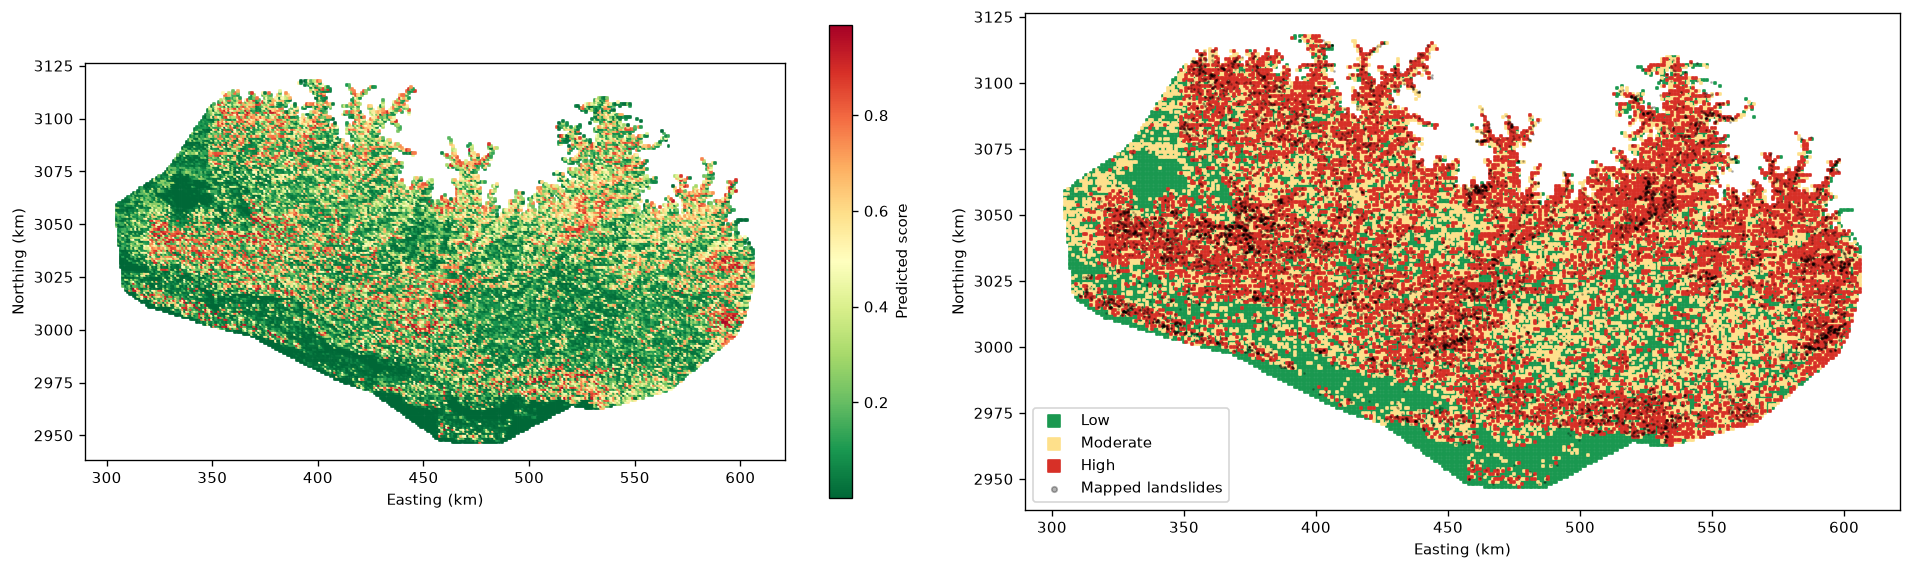

In [33]:
# Visual: continuous probability map and classified risk map side by side
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
sc_ = ax[0].scatter(grid.x / 1000, grid.y / 1000, c=grid.p, s=1.4, marker='s', cmap='RdYlGn_r')
fig.colorbar(sc_, ax=ax[0], shrink=.8, label='Predicted score')
cmap = {'Low': '#1a9850', 'Moderate': '#fee08b', 'High': '#d73027'}
for k, v in cmap.items():
    s = grid[grid['class'] == k]; ax[1].scatter(s.x / 1000, s.y / 1000, s=1.4, c=v, marker='s', label=k)
ax[1].scatter(ls_feat.x / 1000, ls_feat.y / 1000, s=.3, c='k', alpha=.3, label='Mapped landslides')
ax[1].legend(markerscale=6, loc='lower left')
for a in ax: a.set_aspect('equal'); a.set_xlabel('Easting (km)'); a.set_ylabel('Northing (km)')
plt.tight_layout(); savefig('fig12_risk_map')

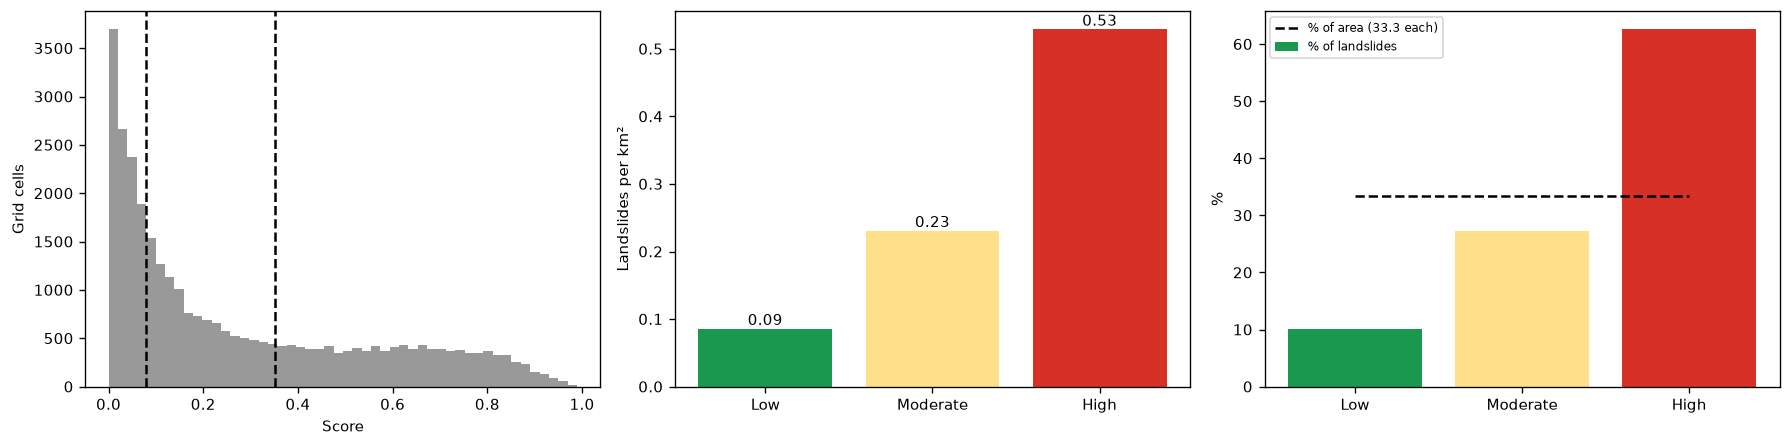

In [34]:
# Visual: does the high class hold more landslides? (density check)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cols = [cmap[c] for c in dens.index]
ax[0].hist(grid.p, bins=50, color='#999999'); [ax[0].axvline(v, c='k', ls='--') for v in (q1, q2)]
ax[0].set_xlabel('Score'); ax[0].set_ylabel('Grid cells')
ax[1].bar(dens.index, dens['landslides_per_km2'], color=cols)
for i, v in enumerate(dens['landslides_per_km2']): ax[1].text(i, v, f'{v:.2f}', ha='center', va='bottom')
ax[1].set_ylabel('Landslides per km²')
ax[2].bar(dens.index, dens['share_of_landslides_%'], color=cols, label='% of landslides')
ax[2].plot(dens.index, [100 / 3] * 3, 'k--', label='% of area (33.3 each)')
ax[2].set_ylabel('%'); ax[2].legend(fontsize=7)
plt.tight_layout(); savefig('fig12b_density_per_class')

## 11. Prototype: predict relative risk for any location
A small intelligent-application prototype: enter a latitude and longitude and get the model's score, relative risk
class, the terrain values it used, and a map showing where the point sits.

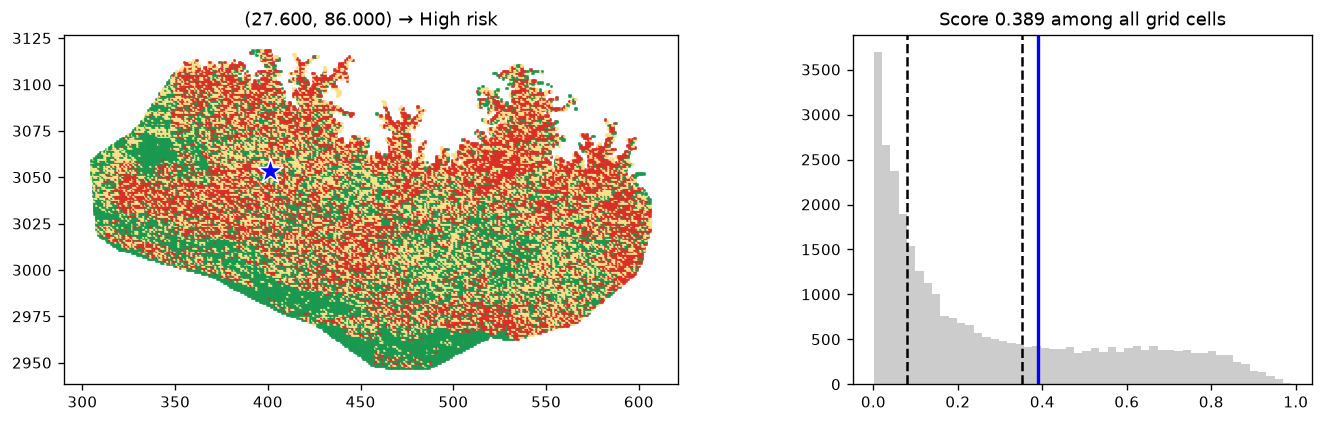

{'score': 0.389,
 'relative_risk': 'High',
 'elevation': 2279.0,
 'slope': 22.9,
 'aspect_sin': 0.6,
 'aspect_cos': -0.8,
 'tri': 31.399999618530273,
 'relief': 162.6999969482422}

In [35]:
def predict_location(lat, lon, show=True):
    t = terrain([lon], [lat])
    if t.isna().any(axis=None):
        return 'Location is outside the DEM extent.'
    x, y_ = to_utm.transform(lon, lat)
    if not area.contains(Point(x, y_)) or t.elevation[0] > MAX_ELEV_M:
        return 'Location is outside the study area or above 4,500 m (outside the model\'s training range).'
    row = t.assign(aspect_sin=np.sin(np.radians(t.aspect)), aspect_cos=np.cos(np.radians(t.aspect)),
                   x_km=x / 1000, y_km=y_ / 1000)
    p = float(score(final, row[FEATURES])[0])
    cls = 'High' if p > q2 else 'Moderate' if p > q1 else 'Low'
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [2, 1]})
        ax[0].scatter(grid.x / 1000, grid.y / 1000, c=grid['class'].map(cmap), s=1, marker='s')
        ax[0].scatter(x / 1000, y_ / 1000, s=250, marker='*', c='blue', edgecolor='w', zorder=5)
        ax[0].set_aspect('equal'); ax[0].set_title(f'({lat:.3f}, {lon:.3f}) → {cls} risk')
        ax[1].hist(grid.p, bins=50, color='#cccccc'); ax[1].axvline(p, c='blue', lw=2)
        [ax[1].axvline(v, c='k', ls='--') for v in (q1, q2)]; ax[1].set_title(f'Score {p:.3f} among all grid cells')
        plt.tight_layout(); plt.show()
    return {'score': round(p, 3), 'relative_risk': cls, **row[TERRAIN].round(1).iloc[0].to_dict()}

# Example: a point in the middle hills of the basin (change to any location)
predict_location(27.6, 86.0)

In [36]:
try:
    import ipywidgets as w
    from IPython.display import display
    la, lo, out = w.FloatText(27.6, description='Latitude'), w.FloatText(86.0, description='Longitude'), w.Output()
    btn = w.Button(description='Predict risk', button_style='danger')
    def _go(_):
        out.clear_output()
        with out:
            print(predict_location(la.value, lo.value))
    btn.on_click(_go)
    display(w.VBox([la, lo, btn, out]))
except Exception as e:
    print('ipywidgets not available:', e)

## 12. Save all results (values for the paper)

{
  "best_model": "Gradient Boosting",
  "spatial_test": {
    "Accuracy": 0.791,
    "Balanced acc.": 0.791,
    "Precision": 0.761,
    "Recall": 0.849,
    "F1": 0.802,
    "ROC-AUC": 0.861,
    "PR-AUC": 0.841,
    "MCC": 0.586,
    "Train AUC": 0.946,
    "CV AUC": 0.85,
    "CV std": 0.015
  },
  "random_split_auc_best": 0.866,
  "auc_inflation_best": 0.005,
  "top_feature": "tri",
  "auc_terrain_only": 0.833
}


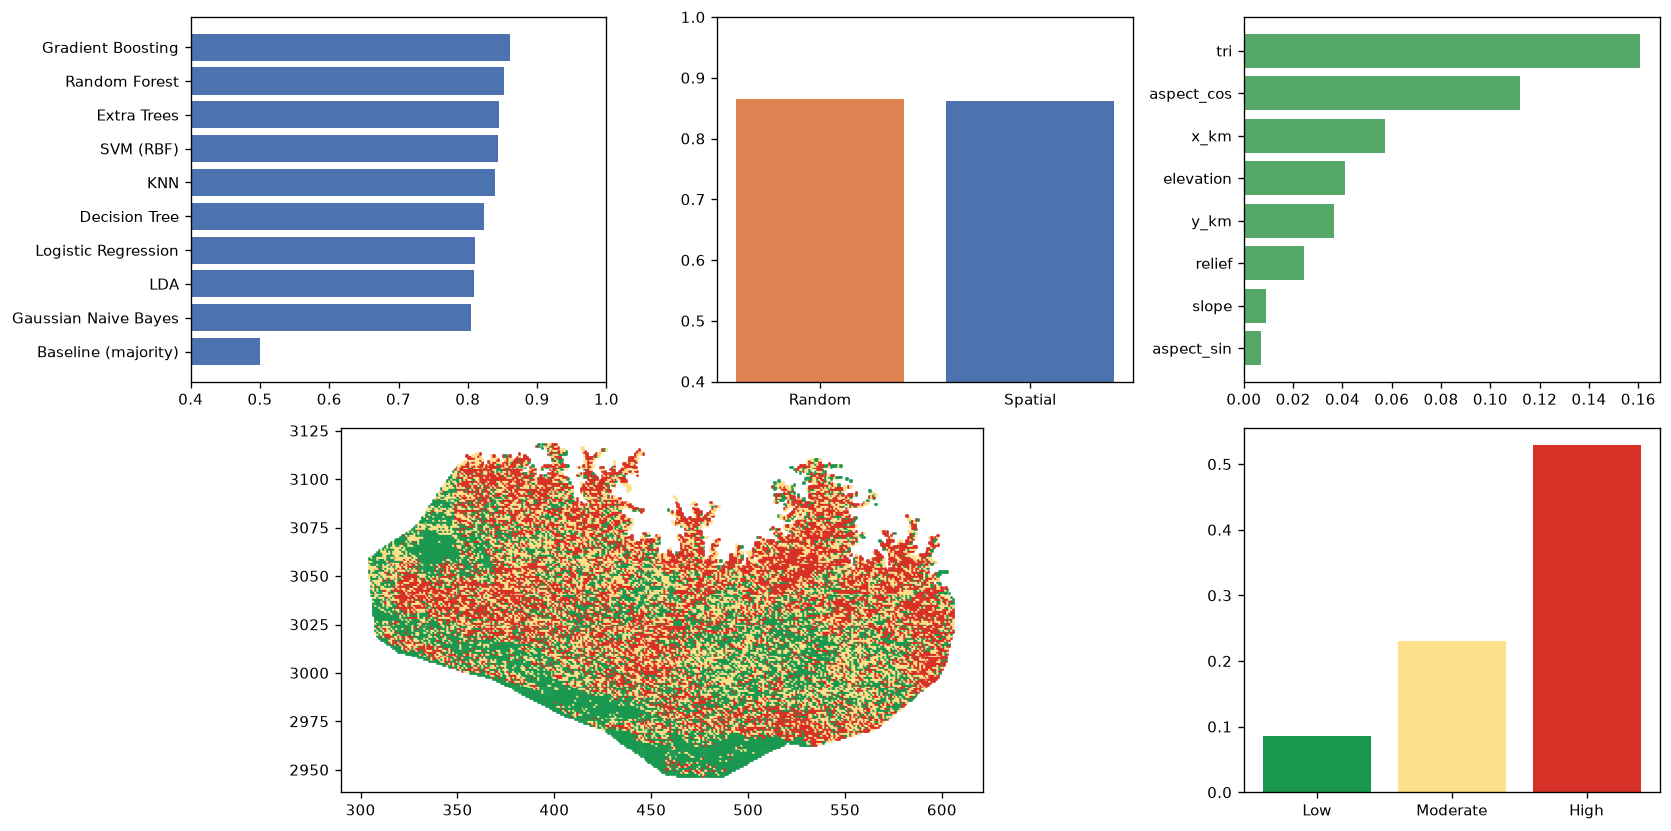


All tables and figures are in the outputs folder.


In [37]:
import json

r0 = res_sp.loc[0]
row_r = cmp.set_index('Model').loc[best_name]
RESULTS.update({
  'best_model': best_name,
  'best_params': spatial[best_name]['params'],
  'spatial_test': {k: round(float(r0[k]), 3) for k in ['Accuracy', 'Balanced acc.', 'Precision', 'Recall', 'F1',
                                                       'ROC-AUC', 'PR-AUC', 'MCC', 'Train AUC', 'CV AUC', 'CV std']},
  'random_split_auc_best': round(float(row_r['ROC-AUC random']), 3),
  'auc_inflation_best': round(float(row_r['AUC inflation']), 3),
  'mean_auc_inflation_all_models': round(float(cmp.loc[cmp.Model != 'Baseline (majority)', 'AUC inflation'].mean()), 3),
  'top_feature': imp.sort_values('importance', ascending=False)['feature'].iloc[0],
  'feature_importance': imp.set_index('feature')['importance'].round(4).to_dict(),
  'auc_terrain_only': round(float(auc_terrain), 3),
  'density_per_class': dens.reset_index().to_dict(orient='records'),
  'all_models_spatial': res_sp.drop(columns='Best params').round(3).to_dict(orient='records'),
})
with open(f'{OUT}/results.json', 'w') as fh:
    json.dump(RESULTS, fh, indent=2, default=str)
print(json.dumps({k: RESULTS[k] for k in ['best_model', 'spatial_test', 'random_split_auc_best', 'auc_inflation_best',
                                          'top_feature', 'auc_terrain_only']}, indent=2, default=str))

# Visual: one-page summary dashboard
fig = plt.figure(figsize=(14, 7))
a1 = fig.add_subplot(2, 3, 1); a1.barh(res_sp['Model'][::-1], res_sp['ROC-AUC'][::-1], color='#4c72b0'); a1.set_xlim(.4, 1)
a2 = fig.add_subplot(2, 3, 2); a2.bar(['Random', 'Spatial'], [row_r['ROC-AUC random'], row_r['ROC-AUC spatial']], color=['#dd8452', '#4c72b0']); a2.set_ylim(.4, 1)
a3 = fig.add_subplot(2, 3, 3); i2 = imp.sort_values('importance'); a3.barh(i2.feature, i2.importance, color='#55a868')
a4 = fig.add_subplot(2, 3, (4, 5)); a4.scatter(grid.x / 1000, grid.y / 1000, c=grid['class'].map(cmap), s=1, marker='s'); a4.set_aspect('equal')
a5 = fig.add_subplot(2, 3, 6); a5.bar(dens.index, dens['landslides_per_km2'], color=[cmap[c] for c in dens.index]); plt.tight_layout()
savefig('fig13_summary_dashboard')
print('\nAll tables and figures are in the', OUT, 'folder.')

In [38]:
import shutil

shutil.make_archive('koshi_outputs', 'zip', OUT)   # one zip with every table and figure
try:
    from google.colab import files
    files.download('koshi_outputs.zip')
except ImportError:
    print('Saved koshi_outputs.zip')

Saved koshi_outputs.zip
